In [2]:
import numpy as np
import time
from scipy.linalg import expm
import scipy as sy
import matplotlib.pyplot as plt
from matplotlib import colors
from numba import jit, cuda
import matplotlib as mpl

sigma_0 = np.array([[1., 0.], [0., 1.]], dtype='complex')
sigma_x = np.array([[0., 1.], [1., 0.]], dtype='complex')
sigma_y = np.array([[0., -1j], [1j, 0.]], dtype='complex')
sigma_z = np.array([[1., 0.], [0.,-1.]], dtype='complex')
np.random.seed(1)

def Calculate_IPR(state):
    # smaller than 1, skin state have O(1/Ly) but corner state have O(1) 'IPR'
    temp_state = np.abs(state) ** 2
    popu_state = temp_state[::2] + temp_state[1::2]
    denominator = np.sum(popu_state) ** 2
    nominator = np.sum(np.abs(popu_state) ** 2)
    return nominator / denominator

def Plot_Lattice1(state, num_xsite, num_ysite, num_sub, pattern='2D', cnorm=None):
    """
    The aim of this function is to plot the edge state or corner state.
    In order to plot the degenerate eigenfunction simultaneously, we save the eigenstate in a dict.
    :param state: dict
        The state we want to plot
    :param num_xsite: the number of site in x direction
    :param num_ysite: the number of site in y direction
    :param num_sub: the number of atoms in one unit cell
    :param pattern: The picture we plot is '2D' or '3D'?
    :return:
    """
    if type(state) == np.ndarray:
        state1 = {}
        state1[0] = state
        state = state1
    # state = np.array(state)
    popu_state = np.zeros((num_xsite * num_ysite))
    for key in state.keys():
        # plot several eigenstate.
        for i in range(num_sub):
            popu_state += np.abs(state[key][i::num_sub]) ** 2
    new_state = popu_state.reshape([num_xsite, num_ysite])
    #new_state = new_state[::-1]

    # 2D
    if pattern == '2D':
        fig = plt.figure(figsize=(10, 8))
        dx = np.arange(0, num_xsite)
        dy = np.arange(0, num_ysite)
        plt.pcolormesh(dx, dy, new_state, cmap='seismic', norm=cnorm)
        plt.colorbar()
        plt.show()
    # 3D
    elif pattern == '3D':
        fig = plt.figure(figsize=(10, 8))
        width = depth = 1
        dx = np.arange(0, num_xsite)
        dy = np.arange(0, num_ysite)
        dx, dy = np.meshgrid(dx, dy)
        dx_l = dx.ravel()
        dy_l = dy.ravel()
        # print(type(x))
        new_state_l = new_state.ravel()
        bottom = np.zeros_like(new_state_l)
        ax1 = fig.add_subplot(111, projection='3d')
        # ax3 = plt.axes(projection='3d')
        ax1.bar3d(dx_l, dy_l, bottom, width, depth, new_state_l, cmap='seismic')
        ax1.set_title('1')
        plt.show()
    else:
        return new_state


def RealHam_QWZ_Dissapation(u, A, gamma, num_xsite, num_ysite, boundary='open', B=1):
    """
    Give out the Hamiltonian in real space of QiWuZhang model.
    :param u: parameter u
    :param A:
    :param num_xsite: how many sites in x direction
    :param num_ysite: how many sites in y direction
    :return:
    """
    ham = np.zeros((2 * num_xsite * num_ysite, 2 * num_xsite * num_ysite), dtype='complex')
    for delta_x in range(num_xsite):
        for delta_y in range(num_ysite):
            row = 2 * (delta_x * num_ysite + delta_y)
            ham[row:row + 2, row:row + 2] = [[u, 0], [0, -u]]
    for delta_x in range(num_xsite - 1):
        for delta_y in range(num_ysite):
            # A site to A site in x direction.
            delta_col = 2 * (delta_x * num_ysite + delta_y)
            delta_row = 2 * ((delta_x + 1) * num_ysite + delta_y)
            ham[delta_row:delta_row + 2, delta_col:delta_col + 2] = [[1 / 2, A * 1j / 2], [A * 1j / 2, -1 / 2]]
            ham[delta_col:delta_col + 2, delta_row:delta_row + 2] = [[1 / 2, -A * 1j / 2], [-A * 1j / 2, -1 / 2]]
    for delta_x in range(num_xsite):
        for delta_y in range(num_ysite - 1):
            # A site to A site
            delta_col = 2 * (delta_x * num_ysite + delta_y)
            delta_row = 2 * ((delta_x) * num_ysite + delta_y + 1)
            ham[delta_row:delta_row + 2, delta_col:delta_col + 2] = [[1 / 2, B / 2], [-B / 2, -1 / 2]]
            ham[delta_col:delta_col + 2, delta_row:delta_row + 2] = [[1 / 2, -B / 2], [B / 2, -1 / 2]]
    if boundary=='close_x':
        # x方向封闭，但是y方向open
        site_constant = 2*num_ysite*(num_xsite-1)
        for i in range(num_ysite):
            ham[2 * i:2 * i + 2, site_constant + 2 * i:site_constant + 2 * i + 2] = [[1 / 2, A * 1j / 2],[A * 1j / 2, -1 / 2]]
            ham[site_constant + 2 * i:site_constant + 2 * i + 2, 2 * i:2 * i + 2] = [[1 / 2, -A * 1j / 2],
                                                                                     [-A * 1j / 2, -1 / 2]]
    if boundary=='close':
        # close x
        site_constant = 2 * num_ysite * (num_xsite - 1)
        for i in range(num_ysite):
            ham[2 * i:2 * i + 2, site_constant + 2 * i:site_constant + 2 * i + 2] = [[1 / 2, A * 1j / 2],[A * 1j / 2, -1 / 2]]
            ham[site_constant + 2 * i:site_constant + 2 * i + 2, 2 * i:2 * i + 2] = [[1 / 2, -A * 1j / 2],[-A * 1j / 2, -1 / 2]]
        # close y
        site_constant = 2 * (num_ysite - 1)
        for i in range(num_xsite):
            ham[2 * i * num_ysite:2 * i * num_ysite + 2,
            2 * i * num_ysite + site_constant:2 * i * num_ysite + 2 + site_constant] = [[1 / 2, 1 / 2], [-1 / 2, -1 / 2]]
            ham[2 * i * num_ysite + site_constant:2 * i * num_ysite + 2 + site_constant,
            2 * i * num_ysite:2 * i * num_ysite + 2] = [[1 / 2, -1 / 2], [1 / 2, -1 / 2]]
    # 在x=0的边界出加decay.  
    # 2 5
    # 1 4
    # 0 3
    # edge dissipation
    # for delta_x in range(num_xsite):
    #     row = 2 * (delta_x * num_ysite + 0)
    #     ham[row:row + 2, row:row + 2] += [[-1j*gamma, 0.], [0., -1j*gamma]]
    # dissipation at the edge y=0,上面写错了
    for delta_y in range(num_xsite):
        row = 2 * (delta_y * num_ysite + 0)
        ham[row:row + 2, row:row + 2] += [[-1j*gamma, 0.], [0., -1j*gamma]]
    return ham

### 不同尺寸

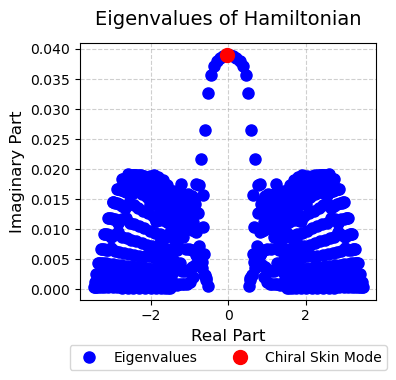

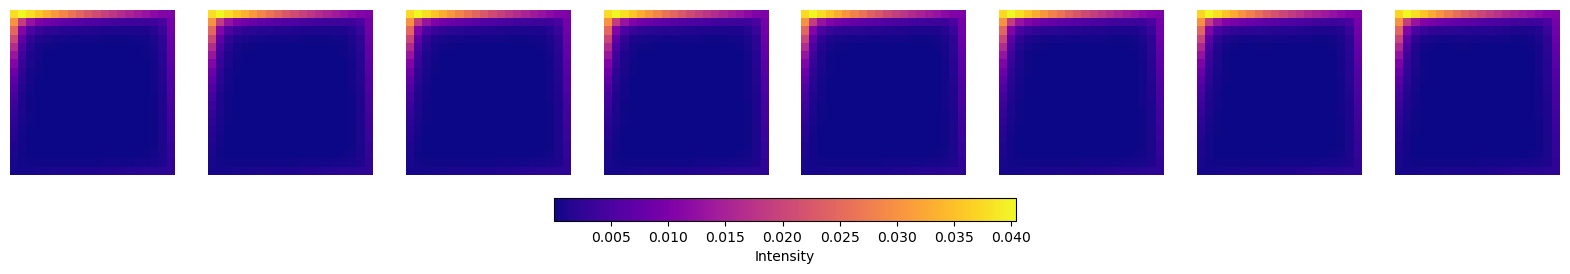

In [22]:
u = -1.5
gamma = -0.2
num_xsite = 20
num_ysite = 20
ham22 = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')
eigval, eigvec = np.linalg.eig(ham22)
eigvec = eigvec[:, np.argsort(np.abs(eigval.real))]
eigval = eigval[np.argsort(np.abs(eigval.real))]
plt.figure(figsize=(4, 4))
plt.plot(eigval.real, eigval.imag, 'o', label='Eigenvalues', markersize=8, color='blue')
plt.plot(eigval[0].real, eigval[0].imag, 'ro', label='Chiral Skin Mode', markersize=10)  # 突出显示基态
plt.grid(True, linestyle='--', alpha=0.6)
plt.xlabel('Real Part', fontsize=12)
plt.ylabel('Imaginary Part', fontsize=12)
plt.title('Eigenvalues of Hamiltonian', fontsize=14, y=1.04)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15),fontsize=10,ncol=2)
plt.tight_layout()
plt.show()


#Plot_Lattice1(eigvec[:, 0], num_xsite, num_ysite, 2, pattern='2D')#, cnorm=vnorm)
# 画出所有本征态
# fig, ax = plt.subplots(1,8, figsize=(20, 3))
# vnorm = mpl.colors.Normalize(vmin=0.2, vmax=0.3)
# for i in range(8):
#     popu_state = np.zeros((num_xsite * num_ysite))
#     popu_state = np.abs(eigvec[::2, i]) ** 2 + np.abs(eigvec[1::2,i]) ** 2
#     new_state = popu_state.reshape([num_xsite, num_ysite])
#     ax[i].imshow(new_state, cmap='seismic', norm=vnorm)
#     #dx = np.arange(0, num_xsite)
#     #dy = np.arange(0, num_ysite)
#     #plt.pcolormesh(dx, dy, new_state, cmap='seismic', norm=vnorm)
#     print(new_state)
# plt.colorbar()
# plt.show()
fig, ax = plt.subplots(1, 8, figsize=(20, 3))
vmin, vmax = 0.2, 0.3  # 统一的颜色范围
# 计算所有数据的最小值和最大值
all_data = []
for i in range(8):
    popu_state = np.abs(eigvec[::2, i]) ** 2 + np.abs(eigvec[1::2, i]) ** 2
    all_data.append(popu_state)
all_data = np.concatenate(all_data)
vmin, vmax = np.min(all_data), np.max(all_data)

color_string = 'plasma'  # 'seismic'这一个就完全使红蓝的。
# 创建一个 ScalarMappable 对象用于 colorbar
sm = plt.cm.ScalarMappable(cmap=color_string, norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
sm.set_array([])  # 空数组，仅用于 colorbar

for i in range(8):
    popu_state = np.zeros((num_xsite * num_ysite))
    popu_state = np.abs(eigvec[::2, i]) ** 2 + np.abs(eigvec[1::2, i]) ** 2
    new_state = popu_state.reshape([num_xsite, num_ysite])
    im = ax[i].imshow(new_state, cmap=color_string, vmin=vmin, vmax=vmax)

    # 在每个格子中心添加数值文本
    # for x in range(num_xsite):
    #     for y in range(num_ysite):
    #         ax[i].text(y, x, f'{new_state[x, y]:.2f}', ha='center', va='center', color='black', fontsize=10)

    ax[i].axis('off')  # 关闭坐标轴

# 添加 colorbar
cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.1, pad=0.1)
cbar.set_label('Intensity')

plt.show()

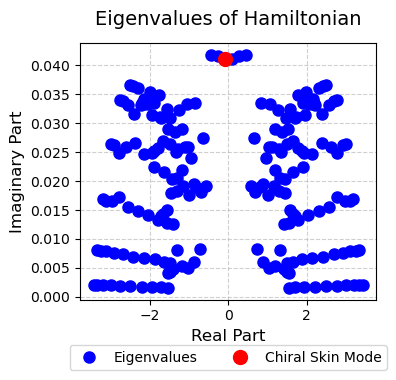

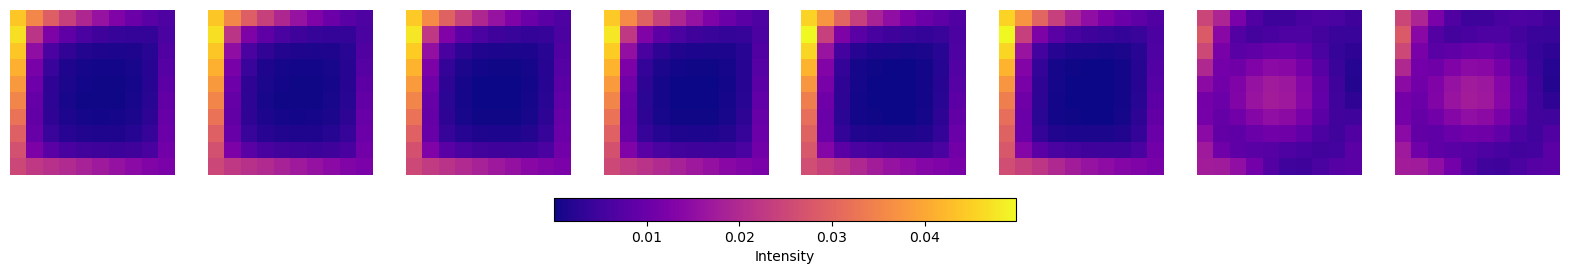

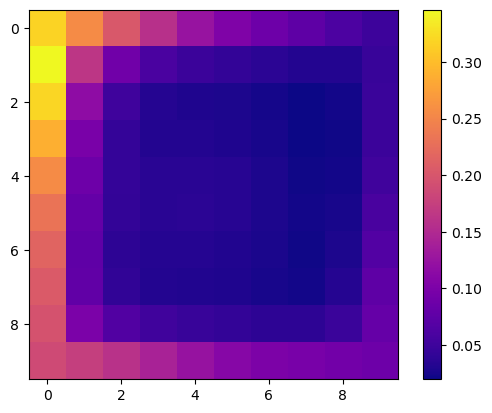

In [114]:
# 耗散类似于加在最右边的边界的。
u = -1.5
gamma = -0.2
num_xsite = 10
num_ysite = 10
ham22 = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')
eigval, eigvec = np.linalg.eig(ham22)
eigvec = eigvec[:, np.argsort(np.abs(eigval.real))]
eigval = eigval[np.argsort(np.abs(eigval.real))]
plt.figure(figsize=(4, 4))
plt.plot(eigval.real, eigval.imag, 'o', label='Eigenvalues', markersize=8, color='blue')
plt.plot(eigval[0].real, eigval[0].imag, 'ro', label='Chiral Skin Mode', markersize=10)  # 突出显示基态
plt.grid(True, linestyle='--', alpha=0.6)
plt.xlabel('Real Part', fontsize=12)
plt.ylabel('Imaginary Part', fontsize=12)
plt.title('Eigenvalues of Hamiltonian', fontsize=14, y=1.04)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15),fontsize=10,ncol=2)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 8, figsize=(20, 3))
vmin, vmax = 0.2, 0.3  # 统一的颜色范围
# 计算所有数据的最小值和最大值
all_data = []
for i in range(8):
    popu_state = np.abs(eigvec[::2, i]) ** 2 + np.abs(eigvec[1::2, i]) ** 2
    all_data.append(popu_state)
all_data = np.concatenate(all_data)
vmin, vmax = np.min(all_data), np.max(all_data)

color_string = 'plasma'  # 'seismic'这一个就完全使红蓝的。
# 创建一个 ScalarMappable 对象用于 colorbar
sm = plt.cm.ScalarMappable(cmap=color_string, norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
sm.set_array([])  # 空数组，仅用于 colorbar

total = np.zeros((num_xsite*num_ysite))
for i in range(8):
    popu_state = np.zeros((num_xsite * num_ysite))
    popu_state = np.abs(eigvec[::2, i]) ** 2 + np.abs(eigvec[1::2, i]) ** 2
    total += popu_state
    new_state = popu_state.reshape([num_xsite, num_ysite]).T
    im = ax[i].imshow(new_state, cmap=color_string, vmin=vmin, vmax=vmax)

    ax[i].axis('off')  # 关闭坐标轴

# 添加 colorbar
cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.1, pad=0.1)
cbar.set_label('Intensity')

plt.show()


total = total.reshape([num_xsite, num_ysite]).T
im = plt.imshow(total, cmap=color_string)
plt.colorbar()
plt.show()

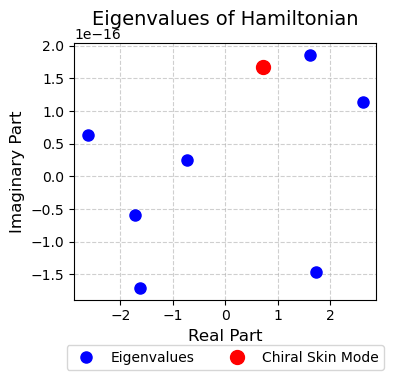

[ 0.72474487+1.67951925e-16j -0.72474487+2.46556880e-17j
 -1.62132034-1.70713516e-16j  1.62132034+1.85850488e-16j
 -1.72474487-5.96660975e-17j  1.72474487-1.45912130e-16j
 -2.62132034+6.39395754e-17j  2.62132034+1.14305309e-16j]


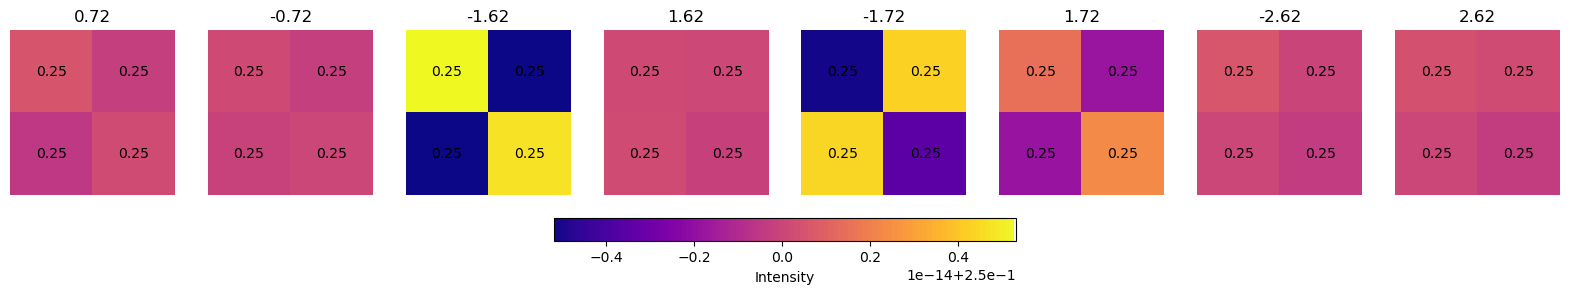

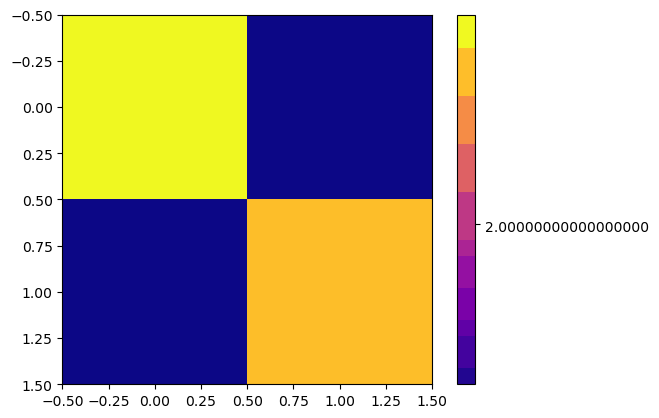

In [ ]:
u = -1.5
gamma = -0.2
num_xsite = 2
num_ysite = 2
ham22 = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')
eigval, eigvec = np.linalg.eig(ham22)
eigvec = eigvec[:, np.argsort(np.abs(eigval.real))]
eigval = eigval[np.argsort(np.abs(eigval.real))]
plt.figure(figsize=(4, 4))
plt.plot(eigval.real, eigval.imag, 'o', label='Eigenvalues', markersize=8, color='blue')
plt.plot(eigval[0].real, eigval[0].imag, 'ro', label='Chiral Skin Mode', markersize=10)  # 突出显示基态
plt.grid(True, linestyle='--', alpha=0.6)
plt.xlabel('Real Part', fontsize=12)
plt.ylabel('Imaginary Part', fontsize=12)
plt.title('Eigenvalues of Hamiltonian', fontsize=14, y=1.04)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15),fontsize=10,ncol=2)
plt.tight_layout()
plt.show()
print(eigval)

fig, ax = plt.subplots(1, 8, figsize=(20, 3))
vmin, vmax = 0.2, 0.3  # 统一的颜色范围
# 计算所有数据的最小值和最大值
all_data = []
for i in range(8):
    popu_state = np.abs(eigvec[::2, i]) ** 2 + np.abs(eigvec[1::2, i]) ** 2
    all_data.append(popu_state)
all_data = np.concatenate(all_data)
vmin, vmax = np.min(all_data), np.max(all_data)

color_string = 'plasma'  # 'seismic'这一个就完全使红蓝的。
# 创建一个 ScalarMappable 对象用于 colorbar
sm = plt.cm.ScalarMappable(cmap=color_string, norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
sm.set_array([])  # 空数组，仅用于 colorbar

total = np.zeros((num_xsite*num_ysite))
for i in range(8):
    popu_state = np.zeros((num_xsite * num_ysite))
    popu_state = np.abs(eigvec[::2, i]) ** 2 + np.abs(eigvec[1::2, i]) ** 2
    total += popu_state
    new_state = popu_state.reshape([num_xsite, num_ysite]).T
    im = ax[i].imshow(new_state, cmap=color_string, vmin=vmin, vmax=vmax)

    # 在每个格子中心添加数值文本
    for x in range(num_xsite):
        for y in range(num_ysite):
            ax[i].text(x,y, f'{new_state[y, x]:.2f}', ha='center', va='center', color='black', fontsize=10)

    ax[i].axis('off')  # 关闭坐标轴
    ax[i].set_title('%.2f'%eigval[i].real)

# 添加 colorbar
cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.1, pad=0.1)
cbar.set_label('Intensity')

plt.show()

total = total.reshape([num_xsite, num_ysite]).T
im = plt.imshow(total, cmap=color_string)
plt.colorbar()
plt.show()


### 随时间的演化

[-1.5+0.1j  1.5+0.1j -1.5+0.j   1.5+0.j  -1.5+0.1j  1.5+0.1j -1.5+0.j
  1.5+0.j ]


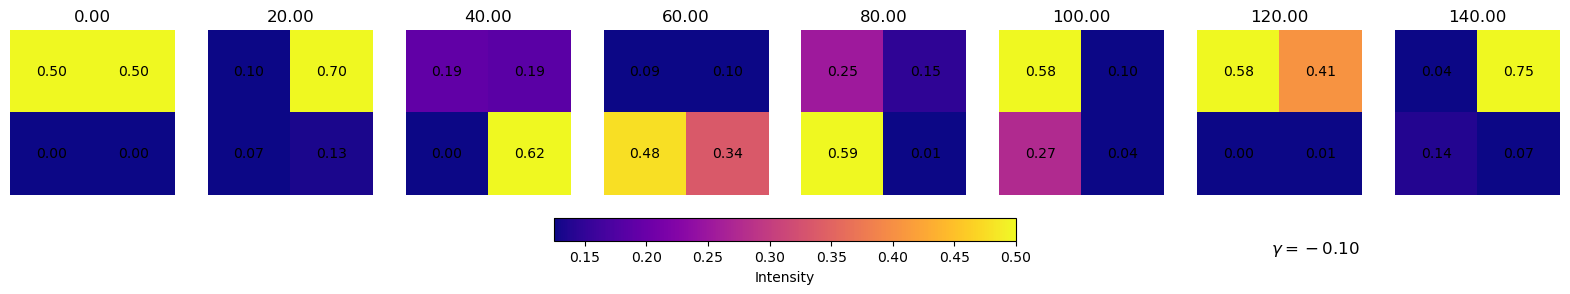

[-1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j]


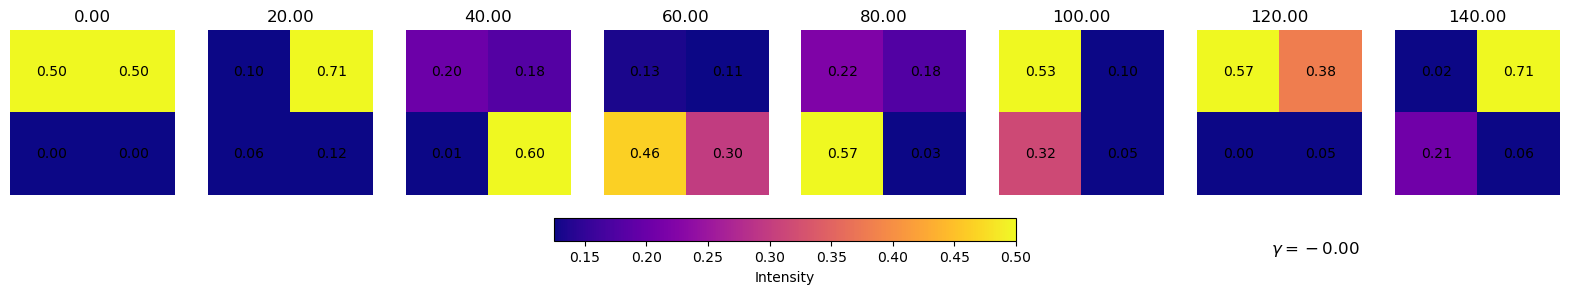

[-1.5+1.j  1.5+1.j -1.5+0.j  1.5+0.j -1.5+1.j  1.5+1.j -1.5+0.j  1.5+0.j]


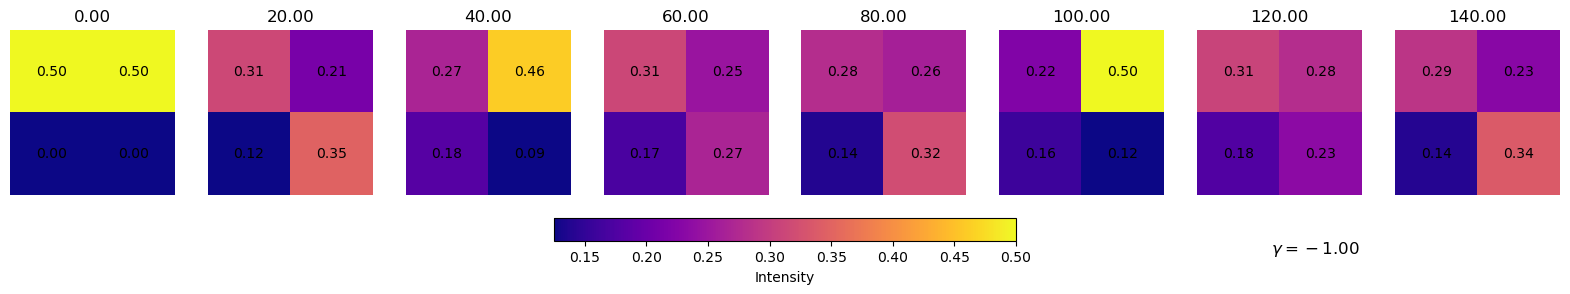

[-1.5+10.j  1.5+10.j -1.5 +0.j  1.5 +0.j -1.5+10.j  1.5+10.j -1.5 +0.j
  1.5 +0.j]


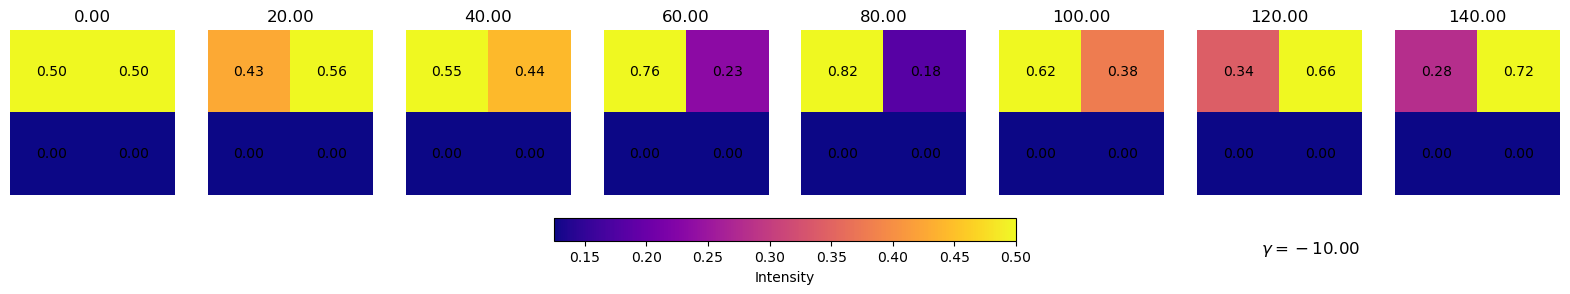

In [ ]:
from scipy.linalg import expm
from scipy.linalg import logm
num_xsite = 2
num_ysite = 2
def temp_fun(gamma,delta_t):
    #gamma = -0.2
    #initial_state = np.ones(2*num_xsite*num_ysite)/np.sqrt(2*num_xsite*num_ysite)
    initial_state = np.array([1,1,0,0,1,1,0,0])/2
    #delta_t = 0.5
    fig, ax = plt.subplots(1, 8, figsize=(20, 3))
    vmin, vmax = 1/(num_xsite*num_ysite) * 0.5, 2/(num_xsite*num_ysite) # 统一的颜色范围
    color_string = 'plasma'  # 'seismic'这一个就完全使红蓝的。
    # 创建一个 ScalarMappable 对象用于 colorbar
    sm = plt.cm.ScalarMappable(cmap=color_string, norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
    sm.set_array([])  # 空数组，仅用于 colorbar

    state = initial_state
    ham22 = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')
    print(np.diag(ham22))
    for i in range(8):
        # state = initial_state
        #state = np.dot(expm(-1j*ham*delta_t), state)
        popu_state = np.zeros((num_xsite * num_ysite))
        popu_state = np.abs(state[::2]) ** 2 + np.abs(state[1::2]) ** 2
        new_state = popu_state.reshape([num_xsite, num_ysite]).T
        im = ax[i].imshow(new_state, cmap=color_string, vmin=vmin, vmax=vmax)

            # 在每个格子中心添加数值文本
        for x in range(num_xsite):
            for y in range(num_ysite):
                ax[i].text(x,y, f'{new_state[y, x]:.2f}', ha='center', va='center', color='black', fontsize=10)

        ax[i].axis('off')  # 关闭坐标轴
        ax[i].set_title('%.2f'%(i*delta_t))
        state = np.dot(expm(-1j*ham22*delta_t), state)
        state = state/np.sqrt(np.sum(np.abs(state)**2))

    # 添加 colorbar
    cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.1, pad=0.1)
    cbar.set_label('Intensity')
    fig.text(0.8, 0.05, r'$\gamma=%.2f$'%(gamma), ha='right', va='bottom', fontsize=12)
    plt.show()
temp_fun(-0.1, 20)
temp_fun(-0., 20)
temp_fun(-1, 20)
temp_fun(-10, 20)

[-1.5+0.1j  1.5+0.1j -1.5+0.j   1.5+0.j  -1.5+0.1j  1.5+0.1j -1.5+0.j
  1.5+0.j ]


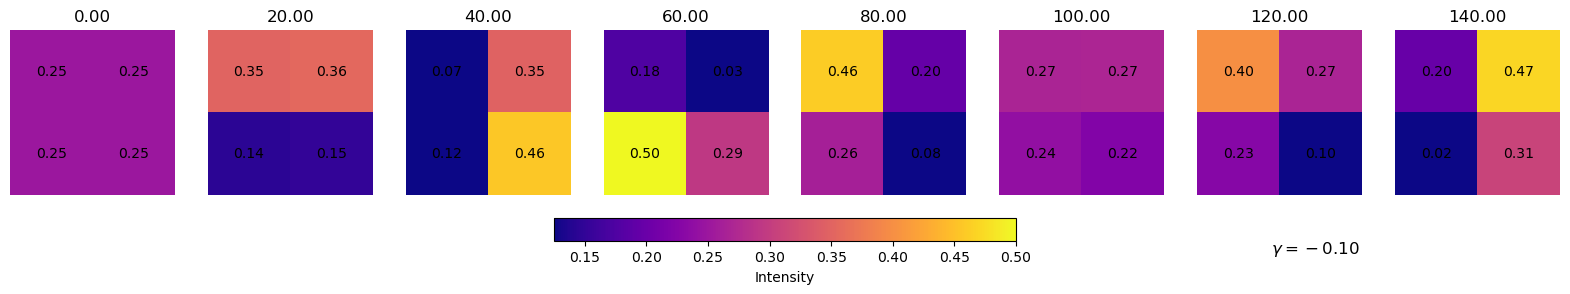

[-1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j]


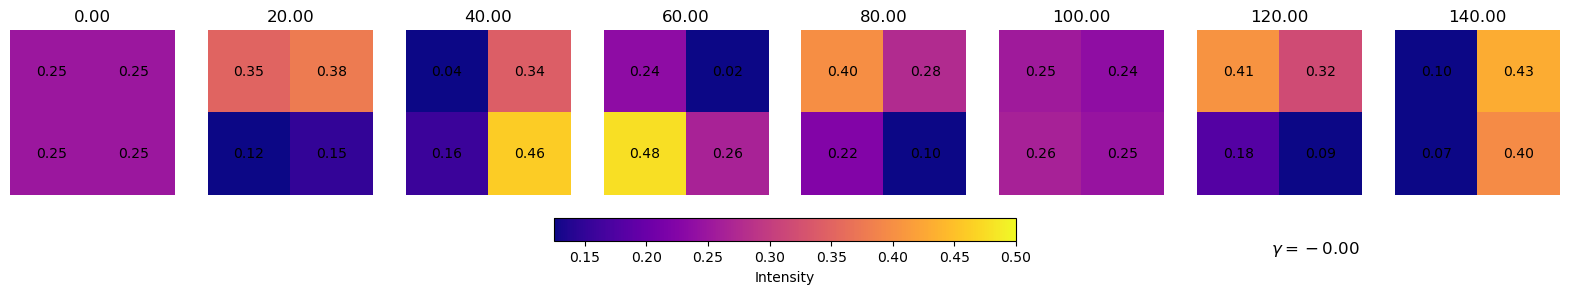

[-1.5+1.j  1.5+1.j -1.5+0.j  1.5+0.j -1.5+1.j  1.5+1.j -1.5+0.j  1.5+0.j]


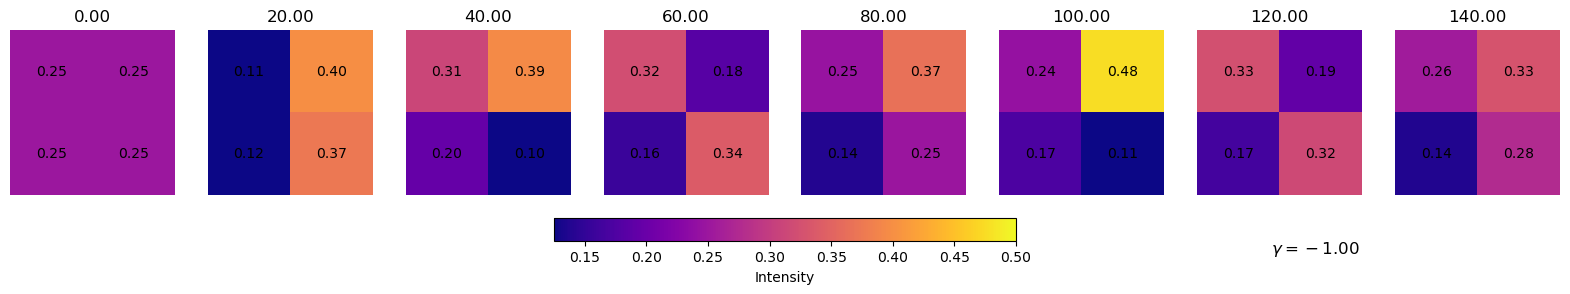

[-1.5+10.j  1.5+10.j -1.5 +0.j  1.5 +0.j -1.5+10.j  1.5+10.j -1.5 +0.j
  1.5 +0.j]


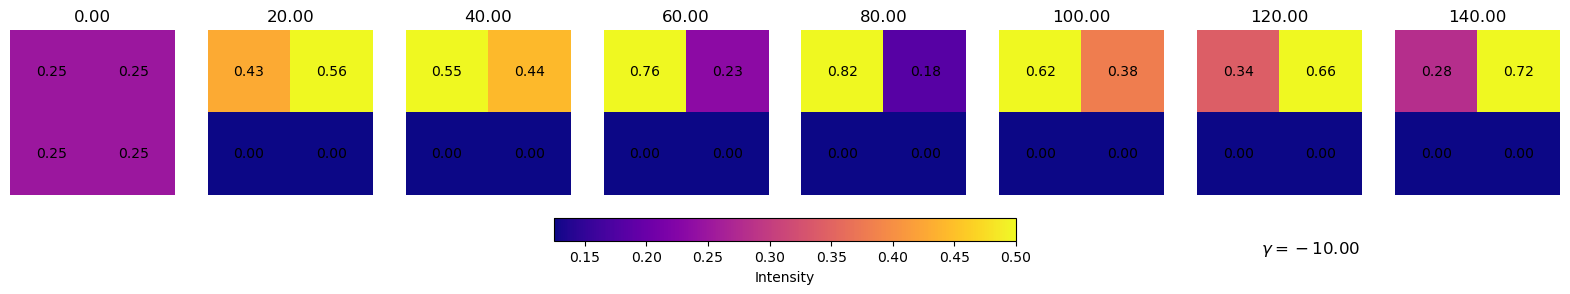

In [129]:
from scipy.linalg import expm
from scipy.linalg import logm
num_xsite = 2
num_ysite = 2
def temp_fun(gamma,delta_t):
    #gamma = -0.2
    #initial_state = np.ones(2*num_xsite*num_ysite)/np.sqrt(2*num_xsite*num_ysite)
    #initial_state = np.array([1,0,0,0,0,0,0,0])
    initial_state = np.ones(8)/np.sqrt(8)
    #delta_t = 0.5
    fig, ax = plt.subplots(1, 8, figsize=(20, 3))
    vmin, vmax = 1/(num_xsite*num_ysite) * 0.5, 2/(num_xsite*num_ysite) # 统一的颜色范围
    color_string = 'plasma'  # 'seismic'这一个就完全使红蓝的。
    # 创建一个 ScalarMappable 对象用于 colorbar
    sm = plt.cm.ScalarMappable(cmap=color_string, norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
    sm.set_array([])  # 空数组，仅用于 colorbar

    state = initial_state
    ham22 = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')
    print(np.diag(ham22))
    for i in range(8):
        # state = initial_state
        #state = np.dot(expm(-1j*ham*delta_t), state)
        popu_state = np.zeros((num_xsite * num_ysite))
        popu_state = np.abs(state[::2]) ** 2 + np.abs(state[1::2]) ** 2
        new_state = popu_state.reshape([num_xsite, num_ysite]).T
        im = ax[i].imshow(new_state, cmap=color_string, vmin=vmin, vmax=vmax)

            # 在每个格子中心添加数值文本
        for x in range(num_xsite):
            for y in range(num_ysite):
                ax[i].text(x,y, f'{new_state[y, x]:.2f}', ha='center', va='center', color='black', fontsize=10)

        ax[i].axis('off')  # 关闭坐标轴
        ax[i].set_title('%.2f'%(i*delta_t))
        state = np.dot(expm(-1j*ham22*delta_t), state)
        state = state/np.sqrt(np.sum(np.abs(state)**2))

    # 添加 colorbar
    cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.1, pad=0.1)
    cbar.set_label('Intensity')
    fig.text(0.8, 0.05, r'$\gamma=%.2f$'%(gamma), ha='right', va='bottom', fontsize=12)
    plt.show()
temp_fun(-0.1, 20)
temp_fun(-0., 20)
temp_fun(-1, 20)
temp_fun(-10, 20)

[-1.5+0.2j  1.5+0.2j -1.5+0.j   1.5+0.j  -1.5+0.2j  1.5+0.2j -1.5+0.j
  1.5+0.j ]


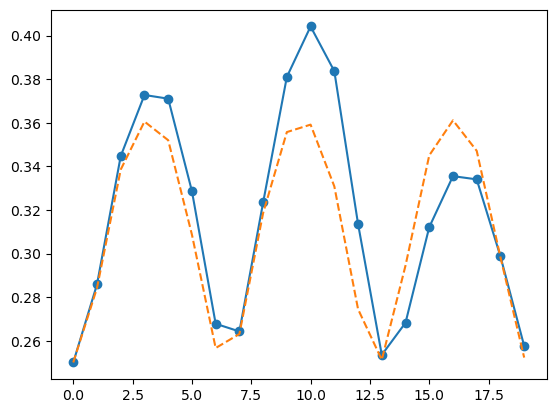

In [136]:
num_xsite = 2
num_ysite = 2
def temp_fun_IPR(gamma,delta_t):
    #gamma = -0.2
    initial_state = np.ones(2*num_xsite*num_ysite)/np.sqrt(2*num_xsite*num_ysite)
    # initial_state = np.array([1,1,0,0,0,0,0,0])/np.sqrt(2)
    # initial_state = np.ones(8)/np.sqrt(8)
    #delta_t = 0.5
    #fig, ax = plt.subplots(1, 8, figsize=(20, 3))
    vmin, vmax = 1/(num_xsite*num_ysite) * 0.5, 2/(num_xsite*num_ysite) # 统一的颜色范围
    color_string = 'plasma'  # 'seismic'这一个就完全使红蓝的。
    # 创建一个 ScalarMappable 对象用于 colorbar
    sm = plt.cm.ScalarMappable(cmap=color_string, norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
    sm.set_array([])  # 空数组，仅用于 colorbar

    state = initial_state
    state_hermi = initial_state
    ham22 = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')
    ham22_Hermi = RealHam_QWZ_Dissapation(u, 1, 0, num_xsite, num_ysite, boundary='open')
    print(np.diag(ham22))
    ipr_list = np.zeros(20)
    ipr_hermi_list = np.zeros(20)
    for i in range(20):
        # state = initial_state
        #state = np.dot(expm(-1j*ham*delta_t), state)
        # popu_state = np.zeros((num_xsite * num_ysite))
        # popu_state = np.abs(state[::2]) ** 2 + np.abs(state[1::2]) ** 2
        # new_state = popu_state.reshape([num_xsite, num_ysite]).T
        # im = ax[i].imshow(new_state, cmap=color_string, vmin=vmin, vmax=vmax)

        #     # 在每个格子中心添加数值文本
        # for x in range(num_xsite):
        #     for y in range(num_ysite):
        #         ax[i].text(x,y, f'{new_state[y, x]:.2f}', ha='center', va='center', color='black', fontsize=10)

        # ax[i].axis('off')  # 关闭坐标轴
        # ax[i].set_title('%.2f'%(i*delta_t))
        ipr_list[i] = Calculate_IPR(state)
        ipr_hermi_list[i] = Calculate_IPR(state_hermi)
        
        state = np.dot(expm(-1j*ham22*delta_t), state)
        state = state/np.sqrt(np.sum(np.abs(state)**2))

        state_hermi = np.dot(expm(-1j*ham22_Hermi*delta_t), state_hermi)
        state_hermi = state_hermi/np.sqrt(np.sum(np.abs(state_hermi)**2))
    # 添加 colorbar
    # cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.1, pad=0.1)
    # cbar.set_label('Intensity')
    # fig.text(0.8, 0.05, r'$\gamma=%.2f$'%(gamma), ha='right', va='bottom', fontsize=12)
    plt.plot(ipr_list,'o-')
    plt.plot(ipr_hermi_list,'--')
    plt.show()
temp_fun_IPR(-0.2, 0.4)

### 2*3的结构

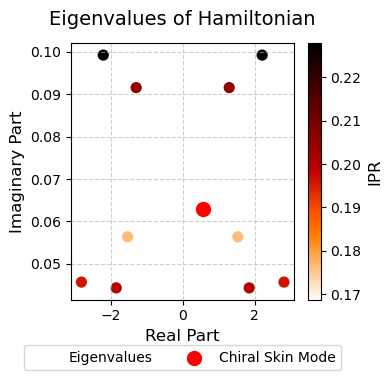

[ 0.57477914+0.06300155j -0.57477914+0.06300155j -1.28947517+0.09154752j
  1.28947517+0.09154752j  1.52616502+0.05632324j -1.52616502+0.05632324j
 -1.8430447 +0.04426613j  1.8430447 +0.04426613j  2.20227838+0.09922699j
 -2.20227838+0.09922699j  2.8071818 +0.04563458j -2.8071818 +0.04563458j]


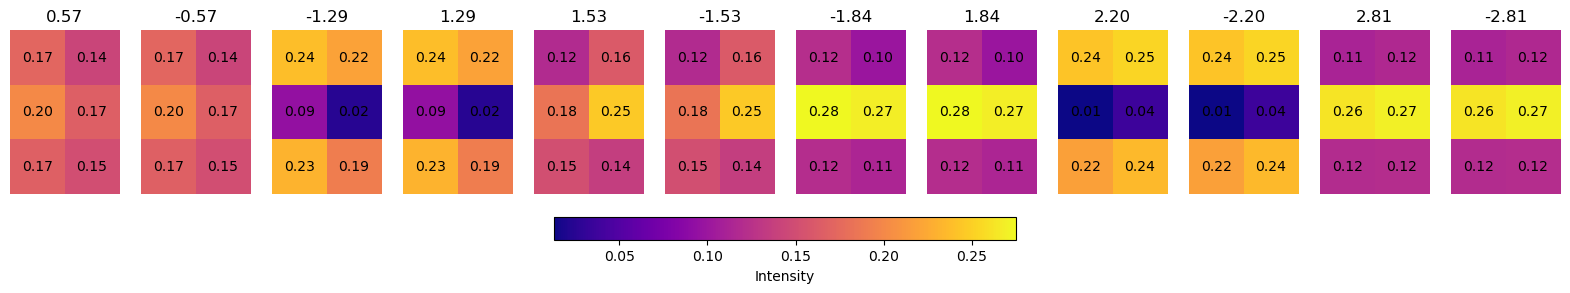

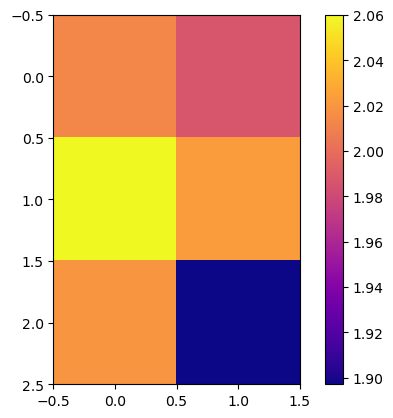

In [156]:
u = -1.5
gamma = -0.2
num_xsite = 2
num_ysite = 3
ham22 = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')
eigval, eigvec = np.linalg.eig(ham22)
eigvec = eigvec[:, np.argsort(np.abs(eigval.real))]
eigval = eigval[np.argsort(np.abs(eigval.real))]
ipr_list = np.zeros(len(eigval))
for i in range(len(eigval)):
    ipr_list[i] = Calculate_IPR(eigvec[:,i])
plt.figure(figsize=(4, 4))
#plt.plot(eigval.real, eigval.imag, 'o', label='Eigenvalues', markersize=8, color='blue')
scatter = plt.scatter(eigval.real, eigval.imag, c=ipr_list, cmap='gist_heat_r', s=50, label='Eigenvalues')

# 突出显示基态
plt.scatter(eigval[0].real, eigval[0].imag, s=100, c='red', marker='o', label='Chiral Skin Mode')

# 添加 colorbar
cbar = plt.colorbar(scatter)
cbar.set_label('IPR', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xlabel('Real Part', fontsize=12)
plt.ylabel('Imaginary Part', fontsize=12)
plt.title('Eigenvalues of Hamiltonian', fontsize=14, y=1.04)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15),fontsize=10,ncol=2)
plt.tight_layout()
plt.show()
print(eigval)

fig, ax = plt.subplots(1, 12, figsize=(20, 3))
vmin, vmax = 0.2, 0.3  # 统一的颜色范围
# 计算所有数据的最小值和最大值
all_data = []
for i in range(12):
    popu_state = np.abs(eigvec[::2, i]) ** 2 + np.abs(eigvec[1::2, i]) ** 2
    all_data.append(popu_state)
all_data = np.concatenate(all_data)
vmin, vmax = np.min(all_data), np.max(all_data)

color_string = 'plasma'  # 'seismic'这一个就完全使红蓝的。
# 创建一个 ScalarMappable 对象用于 colorbar
sm = plt.cm.ScalarMappable(cmap=color_string, norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
sm.set_array([])  # 空数组，仅用于 colorbar

total = np.zeros((num_xsite*num_ysite))
for i in range(12):
    popu_state = np.zeros((num_xsite * num_ysite))
    popu_state = np.abs(eigvec[::2, i]) ** 2 + np.abs(eigvec[1::2, i]) ** 2
    total += popu_state
    new_state = popu_state.reshape([num_xsite, num_ysite]).T
    im = ax[i].imshow(new_state, cmap=color_string, vmin=vmin, vmax=vmax)

    # 在每个格子中心添加数值文本
    for x in range(num_xsite):
        for y in range(num_ysite):
            ax[i].text(x,y, f'{new_state[y, x]:.2f}', ha='center', va='center', color='black', fontsize=10)

    ax[i].axis('off')  # 关闭坐标轴
    ax[i].set_title('%.2f'%eigval[i].real)

# 添加 colorbar
cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.1, pad=0.1)
cbar.set_label('Intensity')

plt.show()

total = total.reshape([num_xsite, num_ysite]).T
im = plt.imshow(total, cmap=color_string)
plt.colorbar()
plt.show()

### 4 * 2结构

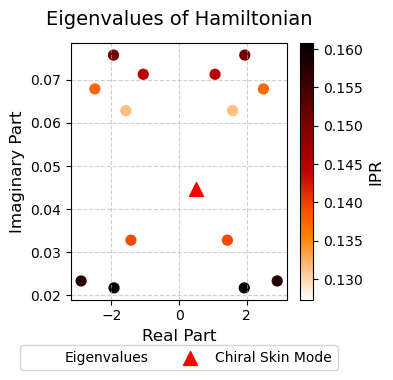

[ 0.48621712+0.04459881j -0.48621712+0.04459881j  1.06031248+0.07124089j
 -1.06031248+0.07124089j -1.42525856+0.03276905j  1.42525856+0.03276905j
  1.57747304+0.06282612j -1.57747304+0.06282612j  1.92438191+0.02170658j
 -1.92438191+0.02170658j  1.9392317 +0.07569321j -1.9392317 +0.07569321j
  2.49040581+0.06785183j -2.49040581+0.06785183j -2.89775672+0.02331352j
  2.89775672+0.02331352j]


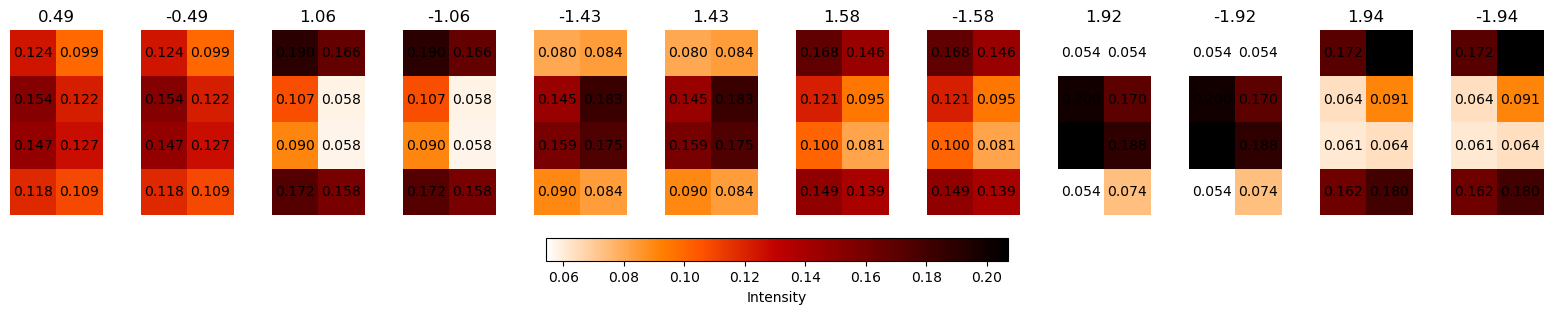

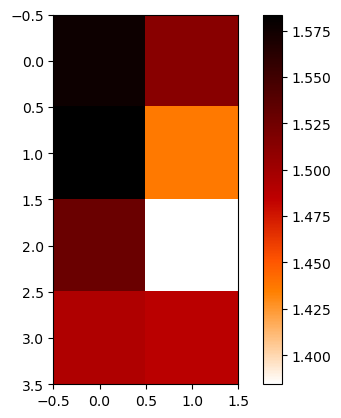

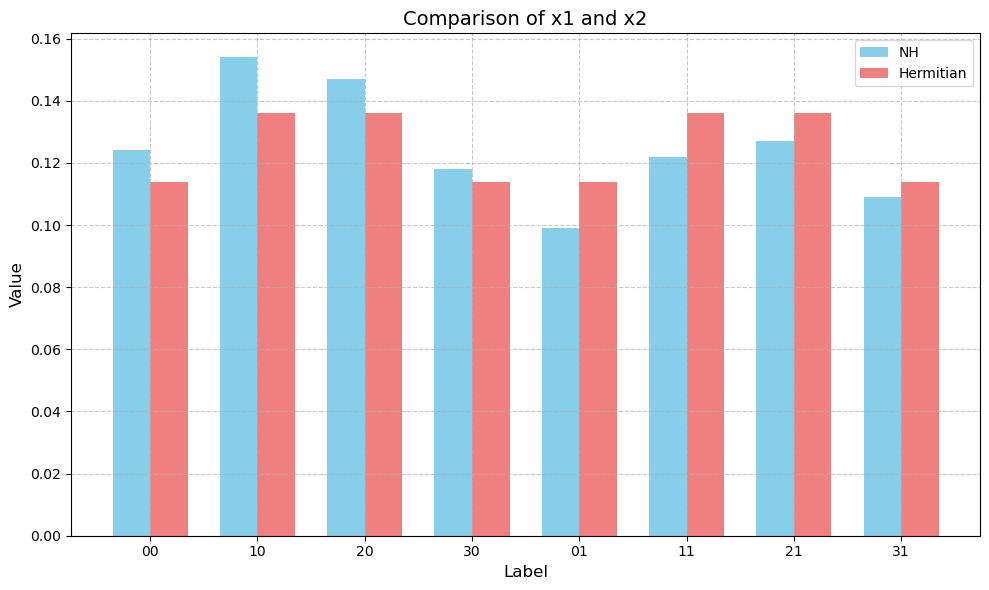

In [428]:
u = -1.5
gamma = -0.2
num_xsite = 2
num_ysite = 4
ham22 = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')
eigval, eigvec = np.linalg.eig(ham22)
eigvec = eigvec[:, np.argsort(np.abs(eigval.real))]
eigval = eigval[np.argsort(np.abs(eigval.real))]
ipr_list = np.zeros(len(eigval))
for i in range(len(eigval)):
    ipr_list[i] = Calculate_IPR(eigvec[:,i])
plt.figure(figsize=(4, 4))
#plt.plot(eigval.real, eigval.imag, 'o', label='Eigenvalues', markersize=8, color='blue')
# color_string = 'plasma'  # 'gist_heat_r'
scatter = plt.scatter(eigval.real, eigval.imag, c=ipr_list,cmap='gist_heat_r', s=50, label='Eigenvalues')

# 突出显示基态
plt.scatter(eigval[0].real, eigval[0].imag, s=100, c='red', marker='^', label='Chiral Skin Mode')

# 添加 colorbar
cbar = plt.colorbar(scatter)
cbar.set_label('IPR', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xlabel('Real Part', fontsize=12)
plt.ylabel('Imaginary Part', fontsize=12)
plt.title('Eigenvalues of Hamiltonian', fontsize=14, y=1.04)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15),fontsize=10,ncol=2)
plt.tight_layout()
plt.show()
print(eigval)

fig, ax = plt.subplots(1, 12, figsize=(20, 3))
vmin, vmax = 0.2, 0.3  # 统一的颜色范围
# 计算所有数据的最小值和最大值
all_data = []
for i in range(12):
    popu_state = np.abs(eigvec[::2, i]) ** 2 + np.abs(eigvec[1::2, i]) ** 2
    all_data.append(popu_state)
all_data = np.concatenate(all_data)
vmin, vmax = np.min(all_data), np.max(all_data)

color_string = 'gist_heat_r' # 'plasma'  # 'seismic'这一个就完全使红蓝的。
# 创建一个 ScalarMappable 对象用于 colorbar
sm = plt.cm.ScalarMappable(cmap=color_string, norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
sm.set_array([])  # 空数组，仅用于 colorbar

total = np.zeros((num_xsite*num_ysite))
for i in range(12):
    popu_state = np.zeros((num_xsite * num_ysite))
    popu_state = np.abs(eigvec[::2, i]) ** 2 + np.abs(eigvec[1::2, i]) ** 2
    total += popu_state
    new_state = popu_state.reshape([num_xsite, num_ysite]).T
    im = ax[i].imshow(new_state, cmap=color_string, vmin=vmin, vmax=vmax)

    # 在每个格子中心添加数值文本
    for x in range(num_xsite):
        for y in range(num_ysite):
            ax[i].text(x,y, f'{new_state[y, x]:.3f}', ha='center', va='center', color='black', fontsize=10)

    ax[i].axis('off')  # 关闭坐标轴
    ax[i].set_title('%.2f'%eigval[i].real)

# 添加 colorbar
cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.1, pad=0.1)
cbar.set_label('Intensity')

plt.show()

total = total.reshape([num_xsite, num_ysite]).T
im = plt.imshow(total, cmap=color_string)
# for x in range(num_xsite):
#     for y in range(num_ysite):
#         plt.text(x,y, f'{total[y, x]:.3f}', ha='center', va='center', color='black', fontsize=10)
plt.colorbar()
plt.show()


#chiral skin
x1 = [0.124, 0.154, 0.147, 0.118, 0.099, 0.122, 0.127, 0.109]
x2 = [0.114, 0.136, 0.136, 0.114, 0.114, 0.136, 0.136, 0.114]
labels = ['00', '10', '20', '30', '01', '11', '21', '31']
# 设置分组柱状图的位置
num_groups = len(x1)
width = 0.35  # 柱子的宽度

# 创建绘图
fig, ax = plt.subplots(figsize=(10, 6))

# 绘制柱状图
x = np.arange(num_groups)
ax.bar(x - width/2, x1, width, label='NH', color='skyblue')
ax.bar(x + width/2, x2, width, label='Hermitian', color='lightcoral')

# 添加标签和标题
ax.set_xlabel('Label', fontsize=12)
ax.set_ylabel('Value', fontsize=12)
ax.set_title('Comparison of x1 and x2', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10)

# 添加图例和网格
ax.legend()
ax.grid(True, linestyle='--', alpha=0.7)

# 调整布局
plt.tight_layout()

# 显示图形
plt.show()

[-1.5+0.2j  1.5+0.2j -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j
  1.5+0.j  -1.5+0.2j  1.5+0.2j -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j
 -1.5+0.j   1.5+0.j ]


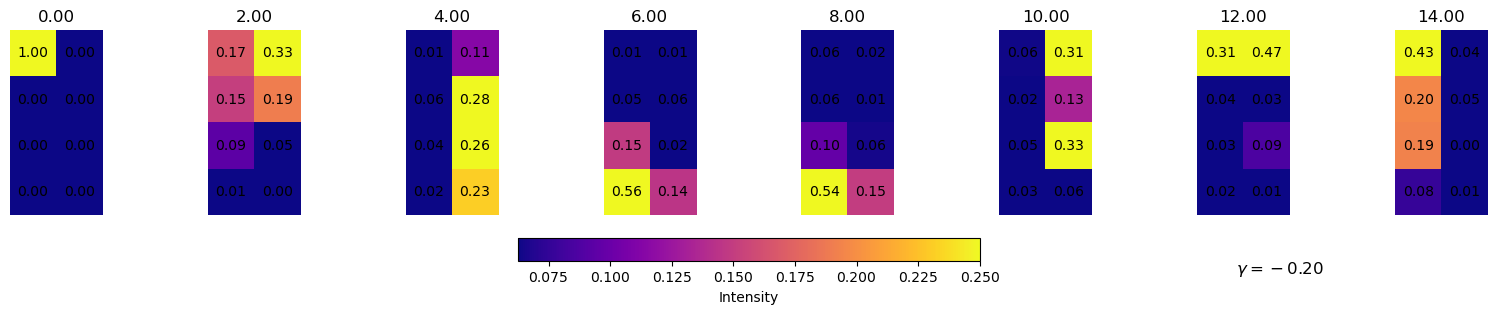

[-1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j
 -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j]


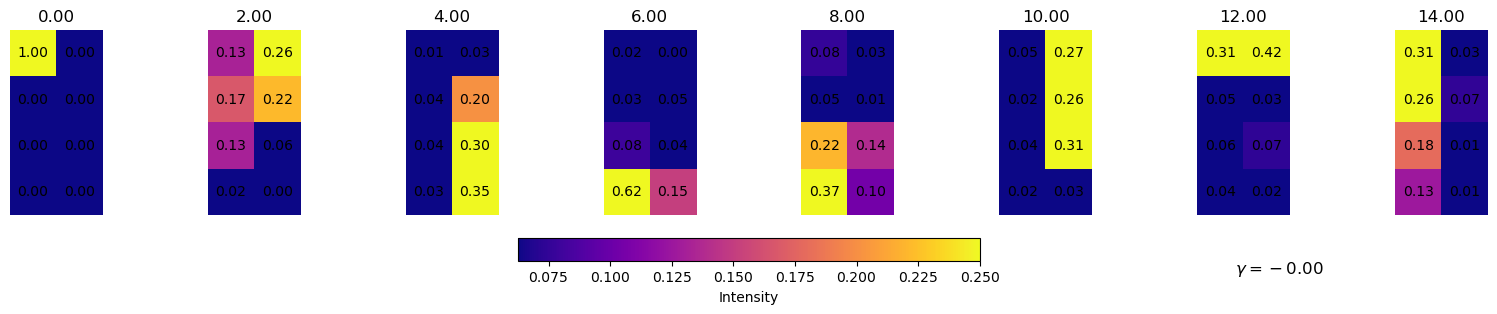

[-1.5+1.j  1.5+1.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j
 -1.5+1.j  1.5+1.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j]


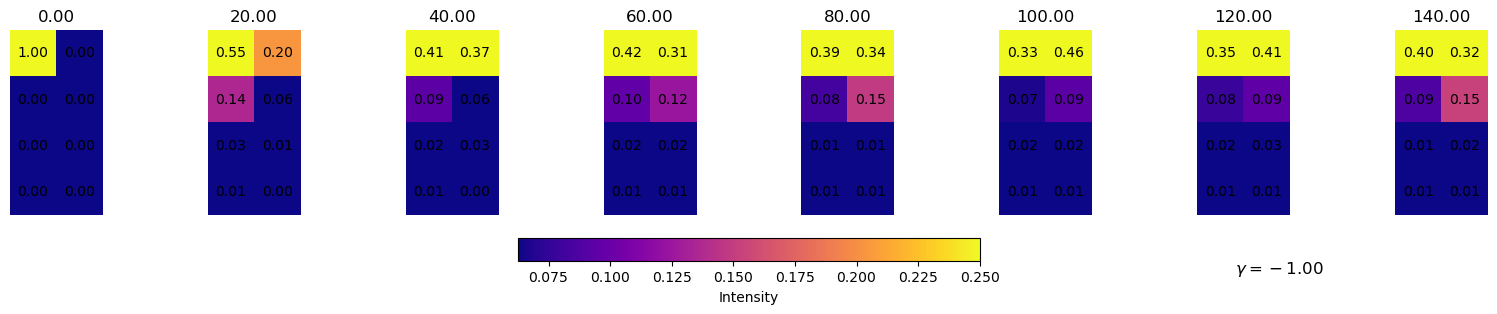

[-1.5+10.j  1.5+10.j -1.5 +0.j  1.5 +0.j -1.5 +0.j  1.5 +0.j -1.5 +0.j
  1.5 +0.j -1.5+10.j  1.5+10.j -1.5 +0.j  1.5 +0.j -1.5 +0.j  1.5 +0.j
 -1.5 +0.j  1.5 +0.j]


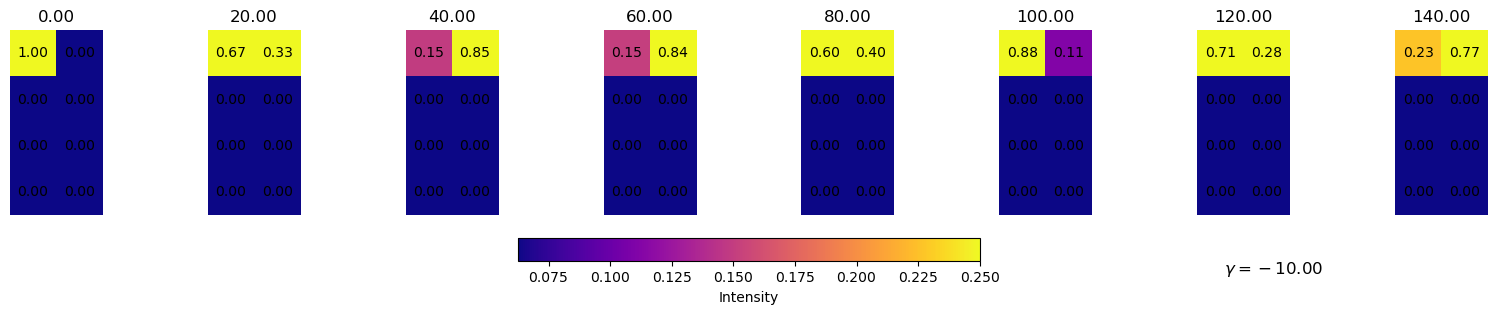

In [285]:
from scipy.linalg import expm
from scipy.linalg import logm
num_xsite = 2
num_ysite = 4
def temp_fun(gamma,delta_t):
    #gamma = -0.2
    #initial_state = np.ones(2*num_xsite*num_ysite)/np.sqrt(2*num_xsite*num_ysite)
    #initial_state = np.array([1,1,0,0,1,1,0,0])/2
    initial_state = np.zeros(2*num_xsite*num_ysite)
    initial_state[0] = 1.
    #initial_state[0], initial_state[1] = 1/np.sqrt(2), 1/np.sqrt(2)
    #delta_t = 0.5
    fig, ax = plt.subplots(1, 8, figsize=(20, 3))
    vmin, vmax = 1/(num_xsite*num_ysite) * 0.5, 2/(num_xsite*num_ysite) # 统一的颜色范围
    color_string = 'plasma'  # 'seismic'这一个就完全使红蓝的。
    # 创建一个 ScalarMappable 对象用于 colorbar
    sm = plt.cm.ScalarMappable(cmap=color_string, norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
    sm.set_array([])  # 空数组，仅用于 colorbar

    state = initial_state
    ham22 = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')
    print(np.diag(ham22))
    for i in range(8):
        # state = initial_state
        #state = np.dot(expm(-1j*ham*delta_t), state)
        popu_state = np.zeros((num_xsite * num_ysite))
        popu_state = np.abs(state[::2]) ** 2 + np.abs(state[1::2]) ** 2
        new_state = popu_state.reshape([num_xsite, num_ysite]).T
        im = ax[i].imshow(new_state, cmap=color_string, vmin=vmin, vmax=vmax)

            # 在每个格子中心添加数值文本
        for x in range(num_xsite):
            for y in range(num_ysite):
                ax[i].text(x,y, f'{new_state[y, x]:.2f}', ha='center', va='center', color='black', fontsize=10)

        ax[i].axis('off')  # 关闭坐标轴
        ax[i].set_title('%.2f'%(i*delta_t))
        state = np.dot(expm(-1j*ham22*delta_t), state)
        state = state/np.sqrt(np.sum(np.abs(state)**2))

    # 添加 colorbar
    cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.1, pad=0.1)
    cbar.set_label('Intensity')
    fig.text(0.8, 0.05, r'$\gamma=%.2f$'%(gamma), ha='right', va='bottom', fontsize=12)
    plt.show()
temp_fun(-0.2, 4)
temp_fun(-0., 4)
temp_fun(-1, 20)
temp_fun(-10, 20)

[-1.5+0.2j  1.5+0.2j -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j
  1.5+0.j  -1.5+0.2j  1.5+0.2j -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j
 -1.5+0.j   1.5+0.j ]


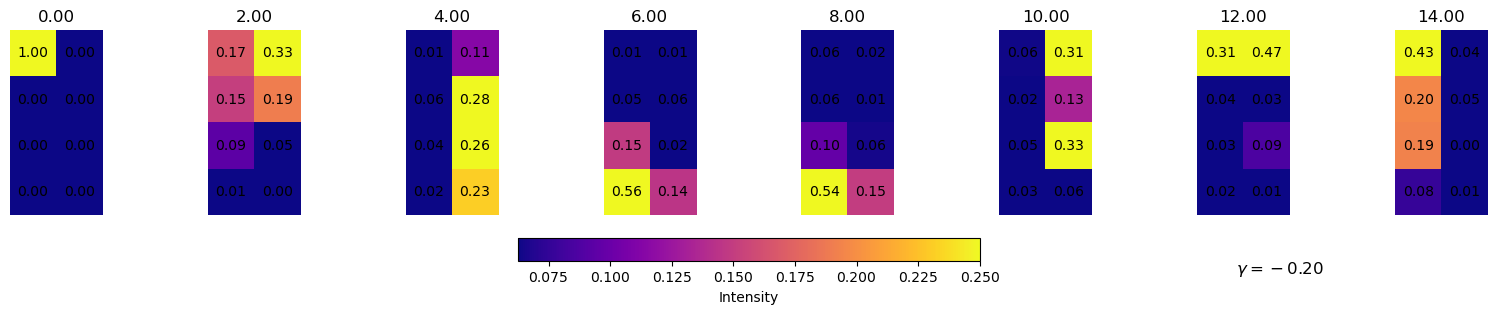

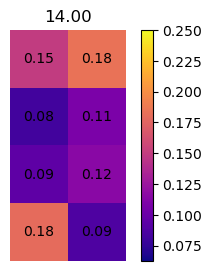

[-1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j
 -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j]


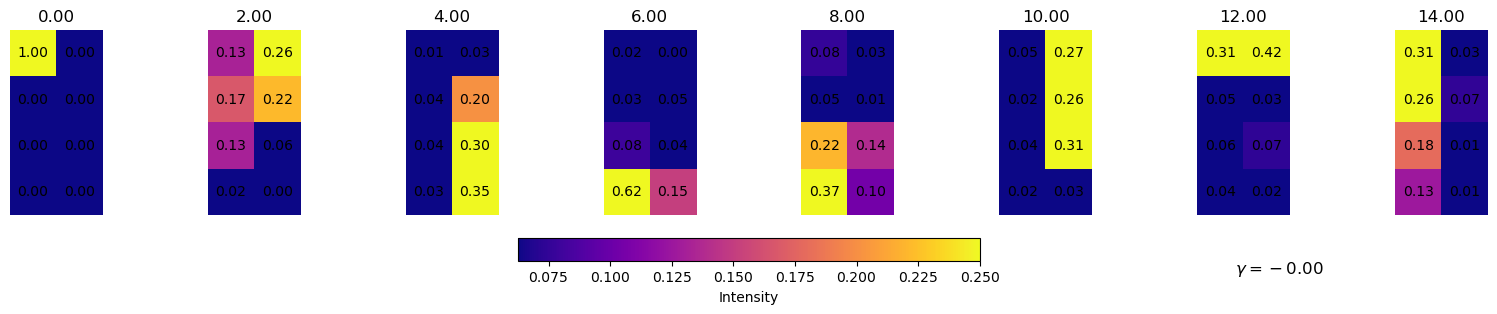

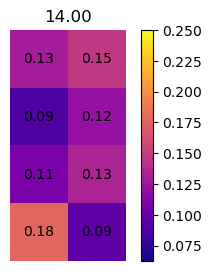

[-1.5+0.2j  1.5+0.2j -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j
  1.5+0.j  -1.5+0.2j  1.5+0.2j -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j
 -1.5+0.j   1.5+0.j ]


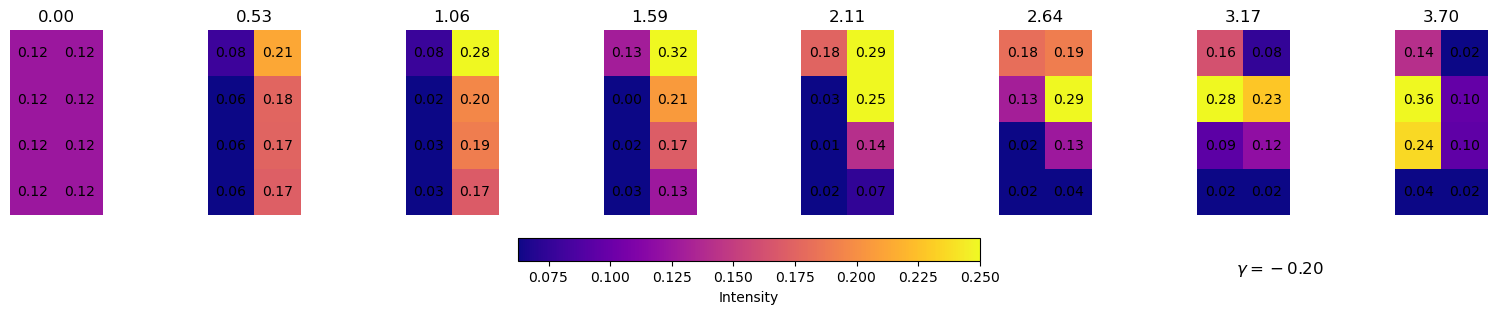

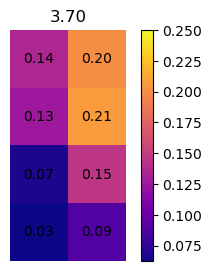

[-1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j
 -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j]


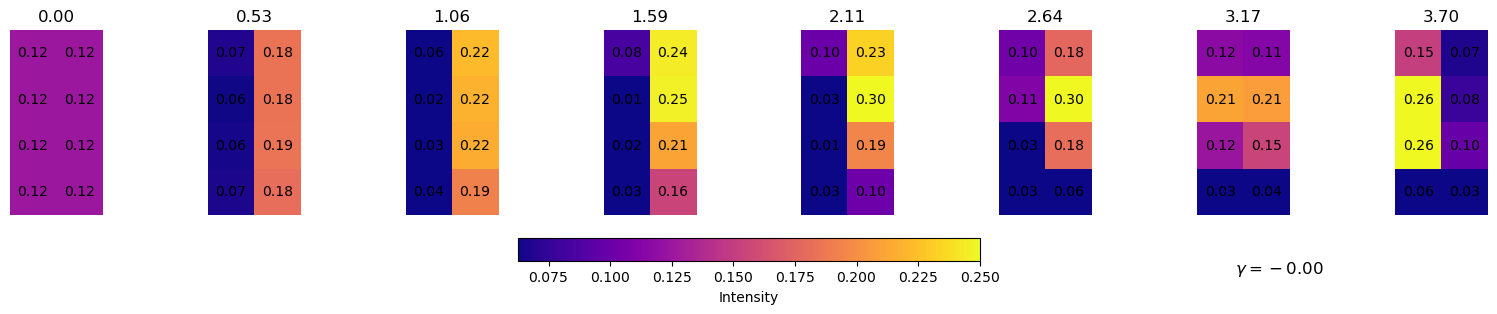

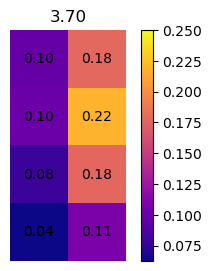

In [327]:
num_xsite = 2
num_ysite = 4
def temp_fun_Total(initial_state, gamma,delta_t):
    #gamma = -0.2
    #initial_state = np.ones(2*num_xsite*num_ysite)/np.sqrt(2*num_xsite*num_ysite)
    #initial_state = np.array([1,1,0,0,1,1,0,0])/2

    #initial_state[0], initial_state[1] = 1/np.sqrt(2), 1/np.sqrt(2)
    #delta_t = 0.5
    fig, ax = plt.subplots(1, 8, figsize=(20, 3))
    vmin, vmax = 1/(num_xsite*num_ysite) * 0.5, 2/(num_xsite*num_ysite) # 统一的颜色范围
    color_string = 'plasma'  # 'seismic'这一个就完全使红蓝的。
    # 创建一个 ScalarMappable 对象用于 colorbar
    sm = plt.cm.ScalarMappable(cmap=color_string, norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
    sm.set_array([])  # 空数组，仅用于 colorbar

    average_state = np.zeros((num_ysite, num_xsite))
    state = initial_state
    ham22 = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')
    print(np.diag(ham22))
    for i in range(len(ax)):
        # state = initial_state
        #state = np.dot(expm(-1j*ham*delta_t), state)
        popu_state = np.zeros((num_xsite * num_ysite))
        popu_state = np.abs(state[::2]) ** 2 + np.abs(state[1::2]) ** 2
        new_state = popu_state.reshape([num_xsite, num_ysite]).T
        im = ax[i].imshow(new_state, cmap=color_string, vmin=vmin, vmax=vmax)
        if i!=0: average_state += new_state

        # 在每个格子中心添加数值文本
        for x in range(num_xsite):
            for y in range(num_ysite):
                ax[i].text(x,y, f'{new_state[y, x]:.2f}', ha='center', va='center', color='black', fontsize=10)

        ax[i].axis('off')  # 关闭坐标轴
        ax[i].set_title('%.2f'%(i*delta_t))
        state = np.dot(expm(-1j*ham22*delta_t), state)
        state = state/np.sqrt(np.sum(np.abs(state)**2))

    # 添加 colorbar
    cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.1, pad=0.1)
    cbar.set_label('Intensity')
    fig.text(0.8, 0.05, r'$\gamma=%.2f$'%(gamma), ha='right', va='bottom', fontsize=12)
    plt.show()

    fig, ax = plt.subplots(1, 1, figsize=(4, 3))
    average_state = average_state/np.sum(average_state)
    im = plt.imshow(average_state, cmap=color_string, vmin=vmin, vmax=vmax)
    # 在每个格子中心添加数值文本
    for x in range(num_xsite):
        for y in range(num_ysite):
            plt.text(x,y, f'{average_state[y, x]:.2f}', ha='center', va='center', color='black', fontsize=10)
    plt.axis('off')  # 关闭坐标轴
    plt.title('%.2f'%(i*delta_t))
    plt.colorbar()
    plt.show()
initial_state = np.zeros(2*num_xsite*num_ysite)
initial_state[0] = 1.
temp_fun_Total(initial_state, -0.2, 2)
temp_fun_Total(initial_state, -0., 2)

#
initial_state = np.ones(2*num_xsite*num_ysite)
initial_state = initial_state/np.sqrt(np.sum(initial_state))
temp_fun_Total(initial_state, -0.2, 3.7/7)
temp_fun_Total(initial_state, -0., 3.7/7)

[-1.5+0.2j  1.5+0.2j -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j
  1.5+0.j  -1.5+0.2j  1.5+0.2j -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j
 -1.5+0.j   1.5+0.j ]
shape: (21,) (4, 2, 21)


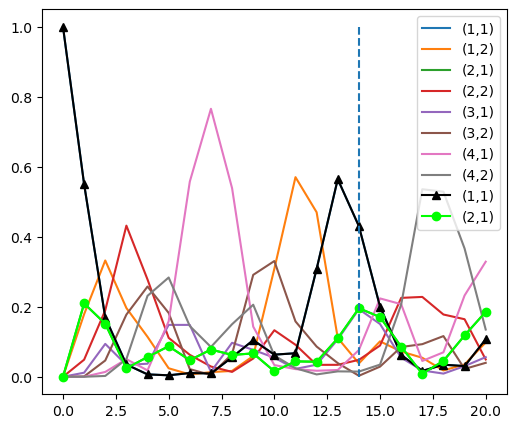

[-1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j
 -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j]
shape: (21,) (4, 2, 21)


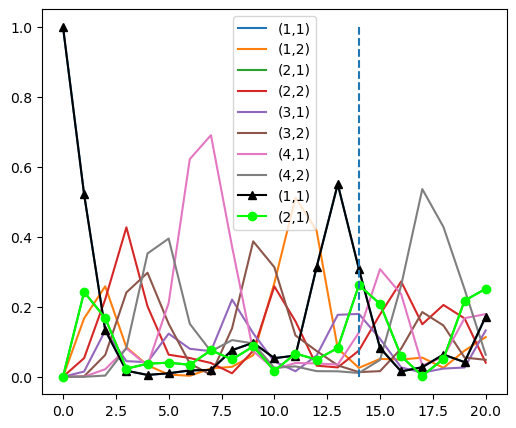

[-1.5-0.2j  1.5-0.2j -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j
  1.5+0.j  -1.5-0.2j  1.5-0.2j -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j
 -1.5+0.j   1.5+0.j ]
shape: (21,) (4, 2, 21)


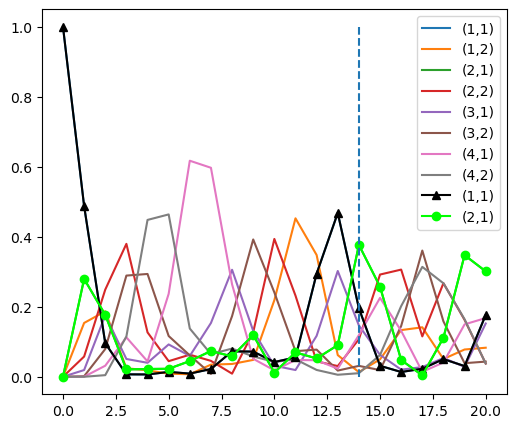

In [360]:
num_xsite = 2
num_ysite = 4
def temp_fun_Evolve(gamma,total_t):
    t_list = np.linspace(0,total_t, 21)
    #gamma = -0.2
    #initial_state = np.ones(2*num_xsite*num_ysite)/np.sqrt(2*num_xsite*num_ysite)
    #initial_state = np.array([1,1,0,0,1,1,0,0])/2
    initial_state = np.zeros(2*num_xsite*num_ysite)
    initial_state[0] = 1.
    #initial_state[0], initial_state[1] = 1/np.sqrt(2), 1/np.sqrt(2)
    #delta_t = 0.5
    #fig, ax = plt.subplots(1, 8, figsize=(20, 3))
    vmin, vmax = 1/(num_xsite*num_ysite) * 0.5, 2/(num_xsite*num_ysite) # 统一的颜色范围
    color_string = 'plasma'  # 'seismic'这一个就完全使红蓝的。
    # 创建一个 ScalarMappable 对象用于 colorbar
    sm = plt.cm.ScalarMappable(cmap=color_string, norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
    sm.set_array([])  # 空数组，仅用于 colorbar

    average_state = np.zeros((num_ysite, num_xsite))
    state = initial_state
    ham22 = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')
    print(np.diag(ham22))
    evo_u = expm(-1j*ham22*t_list[1])
    state_list = np.zeros((num_ysite, num_xsite, len(t_list)))
    for i in range(len(t_list)):
        # state = initial_state
        #state = np.dot(expm(-1j*ham*delta_t), state)
        popu_state = np.zeros((num_xsite * num_ysite))
        popu_state = np.abs(state[::2]) ** 2 + np.abs(state[1::2]) ** 2
        new_state = popu_state.reshape([num_xsite, num_ysite]).T
        #im = ax[i].imshow(new_state, cmap=color_string, vmin=vmin, vmax=vmax)
        state_list[:,:,i] = new_state
        #if i!=0: average_state += new_state

        # 在每个格子中心添加数值文本
        # for x in range(num_xsite):
        #     for y in range(num_ysite):
        #         ax[i].text(x,y, f'{new_state[y, x]:.2f}', ha='center', va='center', color='black', fontsize=10)

        # ax[i].axis('off')  # 关闭坐标轴
        # ax[i].set_title('%.2f'%(i*delta_t))
        state = np.dot(evo_u, state)
        state = state/np.sqrt(np.sum(np.abs(state)**2))

    # 添加 colorbar
    # cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.1, pad=0.1)
    # cbar.set_label('Intensity')
    # fig.text(0.8, 0.05, r'$\gamma=%.2f$'%(gamma), ha='right', va='bottom', fontsize=12)
    # plt.show()

    print('shape:', t_list.shape, state_list.shape)
    fig, ax = plt.subplots(1, 1, figsize=(6, 5))
    for i in range(num_ysite):
        for j in range(num_xsite):
            plt.plot(t_list, state_list[i,j],label='(%d,%d)'%(i+1,j+1))
    plt.plot(t_list, state_list[0,0],'^-',color='k',label='(%d,%d)'%(1,1))
    plt.plot(t_list, state_list[1,0],'o-',color='lime',label='(%d,%d)'%(2,1))
    plt.vlines(14, ymin=0, ymax=1,linestyles='--')
    plt.legend()
    #plt.colorbar()
    plt.show()
temp_fun_Evolve(-0.2, 20)
temp_fun_Evolve(-0., 20)
temp_fun_Evolve(0.2, 20)

[-1.5+0.2j  1.5+0.2j -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j
  1.5+0.j  -1.5+0.2j  1.5+0.2j -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j
 -1.5+0.j   1.5+0.j ]
shape: (21,) (4, 2, 21)


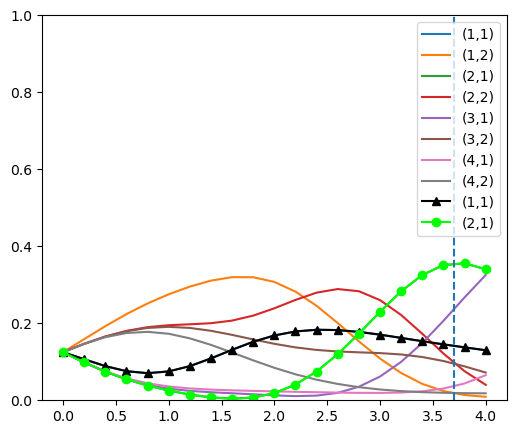

[-1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j
 -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j]
shape: (21,) (4, 2, 21)


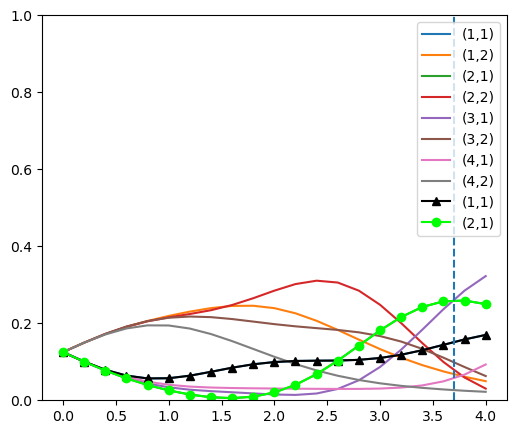

[-1.5-0.2j  1.5-0.2j -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j
  1.5+0.j  -1.5-0.2j  1.5-0.2j -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j
 -1.5+0.j   1.5+0.j ]
shape: (21,) (4, 2, 21)


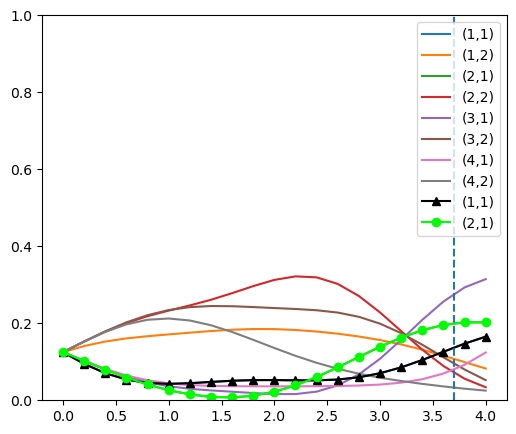

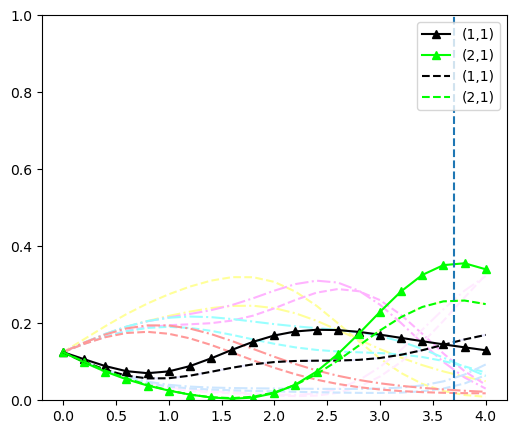

In [430]:
num_xsite = 2
num_ysite = 4
def temp_fun_Evolve(gamma,total_t):
    t_list = np.linspace(0,total_t, 21)
    #gamma = -0.2
    #initial_state = np.ones(2*num_xsite*num_ysite)/np.sqrt(2*num_xsite*num_ysite)
    #initial_state = np.array([1,1,0,0,1,1,0,0])/2
    # initial_state = np.zeros(2*num_xsite*num_ysite)
    # initial_state[0] = 1.
    initial_state = np.ones(2*num_xsite*num_ysite)
    initial_state = initial_state / np.sqrt(np.sum(initial_state))
    #initial_state[0], initial_state[1] = 1/np.sqrt(2), 1/np.sqrt(2)
    #delta_t = 0.5
    #fig, ax = plt.subplots(1, 8, figsize=(20, 3))
    vmin, vmax = 1/(num_xsite*num_ysite) * 0.5, 2/(num_xsite*num_ysite) # 统一的颜色范围
    color_string = 'plasma'  # 'seismic'这一个就完全使红蓝的。
    # 创建一个 ScalarMappable 对象用于 colorbar
    sm = plt.cm.ScalarMappable(cmap=color_string, norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
    sm.set_array([])  # 空数组，仅用于 colorbar

    average_state = np.zeros((num_ysite, num_xsite))
    state = initial_state
    ham22 = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')
    print(np.diag(ham22))
    evo_u = expm(-1j*ham22*t_list[1])
    state_list = np.zeros((num_ysite, num_xsite, len(t_list)))
    for i in range(len(t_list)):
        # state = initial_state
        #state = np.dot(expm(-1j*ham*delta_t), state)
        popu_state = np.zeros((num_xsite * num_ysite))
        popu_state = np.abs(state[::2]) ** 2 + np.abs(state[1::2]) ** 2
        new_state = popu_state.reshape([num_xsite, num_ysite]).T
        #im = ax[i].imshow(new_state, cmap=color_string, vmin=vmin, vmax=vmax)
        state_list[:,:,i] = new_state
        #if i!=0: average_state += new_state

        # 在每个格子中心添加数值文本
        # for x in range(num_xsite):
        #     for y in range(num_ysite):
        #         ax[i].text(x,y, f'{new_state[y, x]:.2f}', ha='center', va='center', color='black', fontsize=10)

        # ax[i].axis('off')  # 关闭坐标轴
        # ax[i].set_title('%.2f'%(i*delta_t))
        state = np.dot(evo_u, state)
        state = state/np.sqrt(np.sum(np.abs(state)**2))

    # 添加 colorbar
    # cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.1, pad=0.1)
    # cbar.set_label('Intensity')
    # fig.text(0.8, 0.05, r'$\gamma=%.2f$'%(gamma), ha='right', va='bottom', fontsize=12)
    # plt.show()

    print('shape:', t_list.shape, state_list.shape)
    fig, ax = plt.subplots(1, 1, figsize=(6, 5))
    for i in range(num_ysite):
        for j in range(num_xsite):
            plt.plot(t_list, state_list[i,j],label='(%d,%d)'%(i+1,j+1))
    plt.plot(t_list, state_list[0,0],'^-',color='k',label='(%d,%d)'%(1,1))
    plt.plot(t_list, state_list[1,0],'o-',color='lime',label='(%d,%d)'%(2,1))
    plt.vlines(3.7, ymin=0, ymax=1,linestyles='--')
    plt.legend()
    plt.ylim(ymin=0, ymax=1)
    #plt.colorbar()
    plt.show()
    return state_list
state1 = temp_fun_Evolve(-0.2, 4)
state2 = temp_fun_Evolve(-0., 4)
temp_fun_Evolve(0.2, 4)

colors = [
    '#e6e6ff',  # 浅蓝色
    '#ffffcc',  # 浅黄色
    '#ffebff',  # 浅粉色
    '#cce6ff',  # 更浅的蓝色
    '#ffff99',  # 浅金黄色
    '#ffb3ff',  # 浅紫色
    '#99ffff',  # 浅青色
    '#ff9999'   # 浅红色
]
t_list = np.linspace(0,4, 21)
fig, ax = plt.subplots(1, 1, figsize=(6, 5))
for i in range(num_ysite):
    for j in range(num_xsite):
        plt.plot(t_list, state1[i,j],'--',color=colors[i+j*4])
        plt.plot(t_list, state2[i,j],'-.',color=colors[i+j*4])
plt.plot(t_list, state1[0,0],'^-',color='k',label='(%d,%d)'%(1,1))
plt.plot(t_list, state1[1,0],'^-',color='lime',label='(%d,%d)'%(2,1))
plt.plot(t_list, state2[0,0],'--',color='k',label='(%d,%d)'%(1,1))
plt.plot(t_list, state2[1,0],'--',color='lime',label='(%d,%d)'%(2,1))
plt.vlines(3.7, ymin=0, ymax=1,linestyles='--')
plt.legend()
plt.ylim(ymin=0, ymax=1)
#plt.colorbar()
plt.show()

[-1.5+0.2j  1.5+0.2j -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j
  1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j
 -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.2j
  1.5+0.2j -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j
 -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j
  1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.2j  1.5+0.2j
 -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j
  1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j
 -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.2j  1.5+0.2j -1.5+0.j
  1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j
 -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j
  1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.2j  1.5+0.2j -1.5+0.j   1.5+0.j
 -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j
  1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j
 -1.5+0.j   1.5+0.

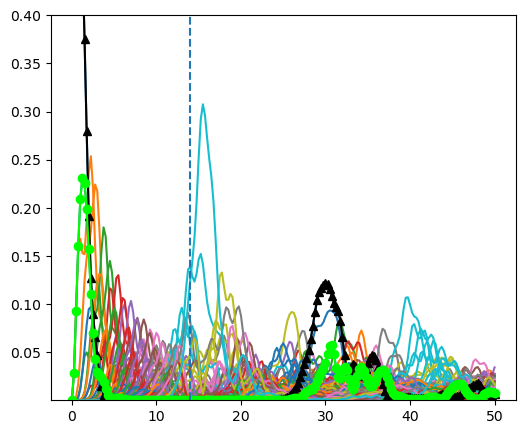

[-1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j
 -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j
 -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j
 -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j
 -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j
 -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j
 -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j
 -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j
 -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j
 -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j
 -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j
 -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j
 -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j
 -1.5+0.j  1.5+0.j -1.5+0.j  1.5+0.j -1.5+0.j  1.5+

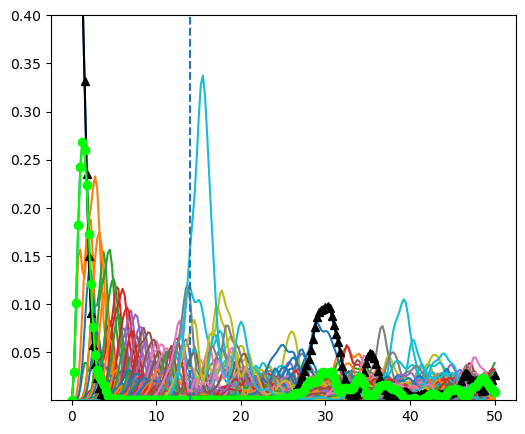

[-1.5-0.2j  1.5-0.2j -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j
  1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j
 -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5-0.2j
  1.5-0.2j -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j
 -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j
  1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5-0.2j  1.5-0.2j
 -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j
  1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j
 -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5-0.2j  1.5-0.2j -1.5+0.j
  1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j
 -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j
  1.5+0.j  -1.5+0.j   1.5+0.j  -1.5-0.2j  1.5-0.2j -1.5+0.j   1.5+0.j
 -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j
  1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j  -1.5+0.j   1.5+0.j
 -1.5+0.j   1.5+0.

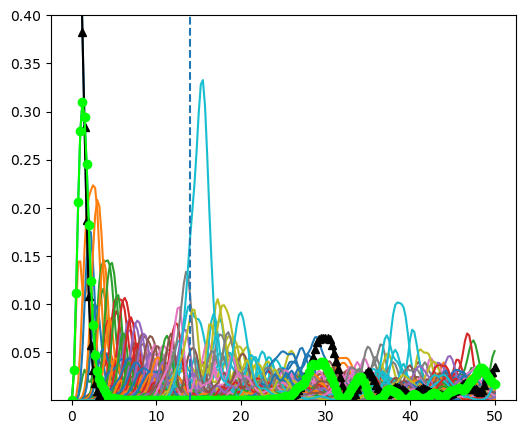

In [321]:
num_xsite = 10
num_ysite = 10
def temp_fun_Evolve(gamma,total_t):
    t_list = np.linspace(0,total_t, 201)
    #gamma = -0.2
    #initial_state = np.ones(2*num_xsite*num_ysite)/np.sqrt(2*num_xsite*num_ysite)
    #initial_state = np.array([1,1,0,0,1,1,0,0])/2
    initial_state = np.zeros(2*num_xsite*num_ysite)
    initial_state[0] = 1.0
    # initial_state = np.ones(2*num_xsite*num_ysite)
    # initial_state = initial_state / np.sqrt(np.sum(initial_state))
    #initial_state[0], initial_state[1] = 1/np.sqrt(2), 1/np.sqrt(2)
    #delta_t = 0.5
    #fig, ax = plt.subplots(1, 8, figsize=(20, 3))
    vmin, vmax = 1/(num_xsite*num_ysite) * 0.5, 2/(num_xsite*num_ysite) # 统一的颜色范围
    color_string = 'plasma'  # 'seismic'这一个就完全使红蓝的。
    # 创建一个 ScalarMappable 对象用于 colorbar
    sm = plt.cm.ScalarMappable(cmap=color_string, norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
    sm.set_array([])  # 空数组，仅用于 colorbar

    average_state = np.zeros((num_ysite, num_xsite))
    state = initial_state
    ham22 = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')
    print(np.diag(ham22))
    evo_u = expm(-1j*ham22*t_list[1])
    state_list = np.zeros((num_ysite, num_xsite, len(t_list)))
    for i in range(len(t_list)):
        # state = initial_state
        #state = np.dot(expm(-1j*ham*delta_t), state)
        popu_state = np.zeros((num_xsite * num_ysite))
        popu_state = np.abs(state[::2]) ** 2 + np.abs(state[1::2]) ** 2
        new_state = popu_state.reshape([num_xsite, num_ysite]).T
        #im = ax[i].imshow(new_state, cmap=color_string, vmin=vmin, vmax=vmax)
        state_list[:,:,i] = new_state
        #if i!=0: average_state += new_state

        # 在每个格子中心添加数值文本
        # for x in range(num_xsite):
        #     for y in range(num_ysite):
        #         ax[i].text(x,y, f'{new_state[y, x]:.2f}', ha='center', va='center', color='black', fontsize=10)

        # ax[i].axis('off')  # 关闭坐标轴
        # ax[i].set_title('%.2f'%(i*delta_t))
        state = np.dot(evo_u, state)
        state = state/np.sqrt(np.sum(np.abs(state)**2))

    # 添加 colorbar
    # cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.1, pad=0.1)
    # cbar.set_label('Intensity')
    # fig.text(0.8, 0.05, r'$\gamma=%.2f$'%(gamma), ha='right', va='bottom', fontsize=12)
    # plt.show()

    print('shape:', t_list.shape, state_list.shape)
    fig, ax = plt.subplots(1, 1, figsize=(6, 5))
    for i in range(num_ysite):
        for j in range(num_xsite):
            plt.plot(t_list, state_list[i,j],label='(%d,%d)'%(i+1,j+1))
    plt.plot(t_list, state_list[0,0],'^-',color='k',label='(%d,%d)'%(1,1))
    plt.plot(t_list, state_list[1,0],'o-',color='lime',label='(%d,%d)'%(2,1))
    plt.vlines(14, ymin=0, ymax=1,linestyles='--')
    #plt.yscale('log')
    plt.ylim(ymin=1e-4,ymax=0.4)
    #plt.legend()
    #plt.colorbar()
    plt.show()
temp_fun_Evolve(-0.2, 50)
temp_fun_Evolve(-0., 50)
temp_fun_Evolve(0.2, 50)

In [295]:
#验证矩阵
alpha = np.exp(-14*0.2)
beta = np.sqrt(1-alpha**2)
U = np.identity(8)
U[0,0] = alpha
U[1,1] = alpha
U[2,2] = alpha
U[3,3] = alpha
U[4,4] = alpha
U[5,5] = alpha

U[0, 1] = beta
U[1, 0] = -beta
U[2, 3] = beta
U[3, 2] = -beta
U[4, 5] = beta
U[5, 4] = -beta
print(U)
print(np.dot(np.conj(U.T),U))


# 在单激发子空间是对易的。其它呢？双激发呢？
num_xsite, num_ysite =2, 4
ham22_non = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')
ham22_1 = RealHam_QWZ_Dissapation(u, 1, 0, num_xsite, num_ysite, boundary='open')
print(np.dot(ham22_non, ham22_1)-np.dot(ham22_1, ham22_non))

[[ 0.06081006  0.99814936  0.          0.          0.          0.
   0.          0.        ]
 [-0.99814936  0.06081006  0.          0.          0.          0.
   0.          0.        ]
 [ 0.          0.          0.06081006  0.99814936  0.          0.
   0.          0.        ]
 [ 0.          0.         -0.99814936  0.06081006  0.          0.
   0.          0.        ]
 [ 0.          0.          0.          0.          0.06081006  0.99814936
   0.          0.        ]
 [ 0.          0.          0.          0.         -0.99814936  0.06081006
   0.          0.        ]
 [ 0.          0.          0.          0.          0.          0.
   1.          0.        ]
 [ 0.          0.          0.          0.          0.          0.
   0.          1.        ]]
[[1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1.]]
[[0.+0.j  0.+0.j  0.+0

In [449]:
num_xsite = 2
num_ysite = 4
u=-1.5
gamma = 0
ham22 = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')
#print(ham22)
def matrix_to_latex(matrix):
    latex_str = 'begin{bmatrix}'
    for row in matrix:
        latex_str += ' & '.join(map(str, row)) + ' \\\\'
    latex_str += 'end{bmatrix}'
    return latex_str

t_list = np.linspace(0, 4, 21)
print(t_list[1])
# print(matrix_to_latex(ham22))
print(matrix_to_latex(np.round(expm(-1j*ham22*t_list[10]),2)))

0.2
begin{bmatrix}(-0.34-0.12j) & (-0.05-0.02j) & (-0.18+0.33j) & (-0.08-0.18j) & (0.12+0.1j) & (-0.02+0.05j) & (0.07-0.01j) & (-0+0.06j) & (-0.04+0.48j) & (-0.21-0j) & (0.51+0.11j) & (-0.17+0.13j) & (0.1-0.2j) & (-0.06+0.1j) & (-0.04-0.04j) & (-0.02-0.01j) \\(-0.05+0.02j) & (-0.34+0.12j) & (-0.08+0.18j) & (-0.18-0.33j) & (-0.02-0.05j) & (0.12-0.1j) & (-0-0.06j) & (0.07+0.01j) & (-0.21+0j) & (-0.04-0.48j) & (-0.17-0.13j) & (0.51-0.11j) & (-0.06-0.1j) & (0.1+0.2j) & (-0.02+0.01j) & (-0.04+0.04j) \\(-0.04+0.35j) & (-0.1-0.19j) & (-0.22-0.16j) & (-0.03-0.04j) & (-0.17+0.25j) & (-0-0.17j) & (0.12+0.1j) & (0.02+0.05j) & (0.51+0.11j) & (-0.17-0.13j) & (-0.22+0.13j) & (-0-0j) & (0.37+0.07j) & (-0.1+0.12j) & (0.08-0.2j) & (-0.07+0.1j) \\(-0.1+0.19j) & (-0.04-0.35j) & (-0.03+0.04j) & (-0.22+0.16j) & (-0+0.17j) & (-0.17-0.25j) & (0.02-0.05j) & (0.12-0.1j) & (-0.17+0.13j) & (0.51-0.11j) & (-0+0j) & (-0.22-0.13j) & (-0.1-0.12j) & (0.37-0.07j) & (-0.07-0.1j) & (0.08+0.2j) \\(0.25+0.11j) & (-0.03-0.


\begin{pmatrix}
(-1.5+0j) & 0j & (0.5+0j) & (-0.5+0j) & 0j & 0j & 0j & 0j & (0.5+0j) & (-0-0.5j) & 0j & 0j & 0j & 0j & 0j & 0j \\
0j & (1.5+0j) & (0.5+0j) & (-0.5+0j) & 0j & 0j & 0j & 0j & (-0-0.5j) & (-0.5+0j) & 0j & 0j & 0j & 0j & 0j & 0j \\
(0.5+0j) & (0.5+0j) & (-1.5+0j) & 0j & (0.5+0j) & (-0.5+0j) & 0j & 0j & 0j & 0j & (0.5+0j) & (-0-0.5j) & 0j & 0j & 0j & 0j \\
(-0.5+0j) & (-0.5+0j) & 0j & (1.5+0j) & (0.5+0j) & (-0.5+0j) & 0j & 0j & 0j & 0j & (-0-0.5j) & (-0.5+0j) & 0j & 0j & 0j & 0j \\
0j & 0j & (0.5+0j) & (0.5+0j) & (-1.5+0j) & 0j & (0.5+0j) & (-0.5+0j) & 0j & 0j & 0j & 0j & (0.5+0j) & (-0-0.5j) & 0j & 0j \\
0j & 0j & (-0.5+0j) & (-0.5+0j) & 0j & (1.5+0j) & (0.5+0j) & (-0.5+0j) & 0j & 0j & 0j & 0j & (-0-0.5j) & (-0.5+0j) & 0j & 0j \\
0j & 0j & 0j & 0j & (0.5+0j) & (0.5+0j) & (-1.5+0j) & 0j & 0j & 0j & 0j & 0j & 0j & 0j & (0.5+0j) & (-0-0.5j) \\
0j & 0j & 0j & 0j & (-0.5+0j) & (-0.5+0j) & 0j & (1.5+0j) & 0j & 0j & 0j & 0j & 0j & 0j & (-0-0.5j) & (-0.5+0j) \\
(0.5+0j) & 0.5j & 0j & 0j & 0j & 0j & 0j & 0j & (-1.5+0j) & 0j & (0.5+0j) & (-0.5+0j) & 0j & 0j & 0j & 0j \\
0.5j & (-0.5+0j) & 0j & 0j & 0j & 0j & 0j & 0j & 0j & (1.5+0j) & (0.5+0j) & (-0.5+0j) & 0j & 0j & 0j & 0j \\
0j & 0j & (0.5+0j) & 0.5j & 0j & 0j & 0j & 0j & (0.5+0j) & (0.5+0j) & (-1.5+0j) & 0j & (0.5+0j) & (-0.5+0j) & 0j & 0j \\
0j & 0j & 0.5j & (-0.5+0j) & 0j & 0j & 0j & 0j & (-0.5+0j) & (-0.5+0j) & 0j & (1.5+0j) & (0.5+0j) & (-0.5+0j) & 0j & 0j \\
0j & 0j & 0j & 0j & (0.5+0j) & 0.5j & 0j & 0j & 0j & 0j & (0.5+0j) & (0.5+0j) & (-1.5+0j) & 0j & (0.5+0j) & (-0.5+0j) \\
0j & 0j & 0j & 0j & 0.5j & (-0.5+0j) & 0j & 0j & 0j & 0j & (-0.5+0j) & (-0.5+0j) & 0j & (1.5+0j) & (0.5+0j) & (-0.5+0j) \\
0j & 0j & 0j & 0j & 0j & 0j & (0.5+0j) & 0.5j & 0j & 0j & 0j & 0j & (0.5+0j) & (0.5+0j) & (-1.5+0j) & 0j \\
0j & 0j & 0j & 0j & 0j & 0j & 0.5j & (-0.5+0j) & 0j & 0j & 0j & 0j & (-0.5+0j) & (-0.5+0j) & 0j & (1.5+0j)
\end{pmatrix}

### 3*3结构

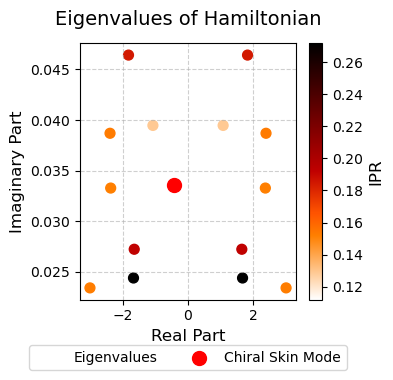

[-0.43395037+0.03352799j  0.43395037+0.03352799j -1.07820114+0.03946468j
  1.07820114+0.03946468j -1.25225764+0.03365119j  1.25225764+0.03365119j
  1.65192671+0.02721442j -1.65192671+0.02721442j  1.67414751+0.02437026j
 -1.67414751+0.02437026j -1.82757813+0.04642332j  1.82757813+0.04642332j
 -2.37444478+0.03326815j  2.37444478+0.03326815j  2.39490278+0.03868819j
 -2.39490278+0.03868819j -3.01102202+0.02339179j  3.01102202+0.02339179j]


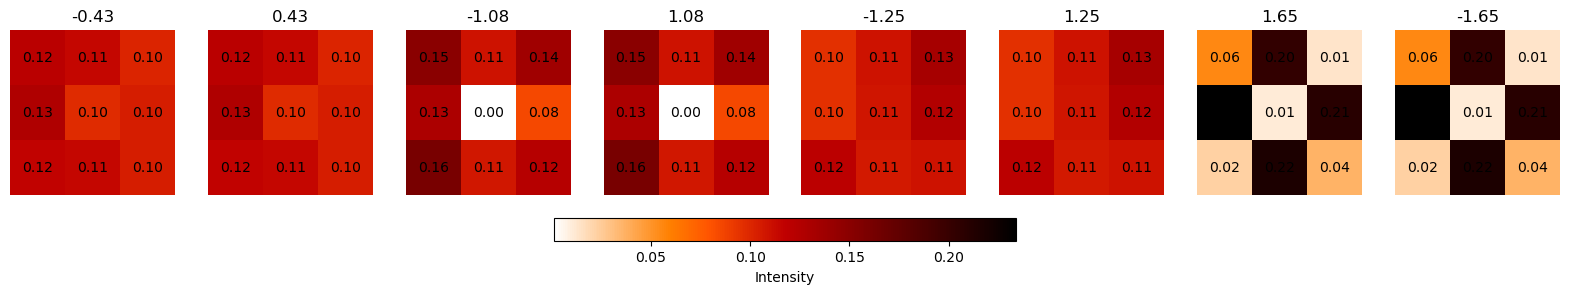

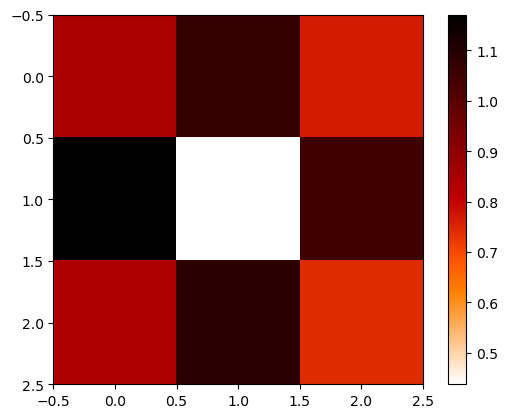

In [195]:
u = -1.5
gamma = -0.1
num_xsite = 3
num_ysite = 3
ham22 = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')
eigval, eigvec = np.linalg.eig(ham22)
eigvec = eigvec[:, np.argsort(np.abs(eigval.real))]
eigval = eigval[np.argsort(np.abs(eigval.real))]
ipr_list = np.zeros(len(eigval))
for i in range(len(eigval)):
    ipr_list[i] = Calculate_IPR(eigvec[:,i])
plt.figure(figsize=(4, 4))
#plt.plot(eigval.real, eigval.imag, 'o', label='Eigenvalues', markersize=8, color='blue')
scatter = plt.scatter(eigval.real, eigval.imag, c=ipr_list, cmap='gist_heat_r', s=50, label='Eigenvalues')

# 突出显示基态
plt.scatter(eigval[0].real, eigval[0].imag, s=100, c='red', marker='o', label='Chiral Skin Mode')

# 添加 colorbar
cbar = plt.colorbar(scatter)
cbar.set_label('IPR', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xlabel('Real Part', fontsize=12)
plt.ylabel('Imaginary Part', fontsize=12)
plt.title('Eigenvalues of Hamiltonian', fontsize=14, y=1.04)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15),fontsize=10,ncol=2)
plt.tight_layout()
plt.show()
print(eigval)

num_eigenstate = 8
fig, ax = plt.subplots(1, num_eigenstate, figsize=(20, 3))
vmin, vmax = 0.2, 0.3  # 统一的颜色范围
# 计算所有数据的最小值和最大值
all_data = []
for i in range(num_eigenstate):
    popu_state = np.abs(eigvec[::2, i]) ** 2 + np.abs(eigvec[1::2, i]) ** 2
    all_data.append(popu_state)
all_data = np.concatenate(all_data)
vmin, vmax = np.min(all_data), np.max(all_data)

color_string = 'gist_heat_r'#'plasma'  # 'seismic'这一个就完全使红蓝的。
# 创建一个 ScalarMappable 对象用于 colorbar
sm = plt.cm.ScalarMappable(cmap=color_string, norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
sm.set_array([])  # 空数组，仅用于 colorbar

total = np.zeros((num_xsite*num_ysite))
for i in range(num_eigenstate):
    popu_state = np.zeros((num_xsite * num_ysite))
    popu_state = np.abs(eigvec[::2, i]) ** 2 + np.abs(eigvec[1::2, i]) ** 2
    total += popu_state
    new_state = popu_state.reshape([num_xsite, num_ysite]).T
    im = ax[i].imshow(new_state, cmap=color_string, vmin=vmin, vmax=vmax)

    # 在每个格子中心添加数值文本
    for x in range(num_xsite):
        for y in range(num_ysite):
            ax[i].text(x,y, f'{new_state[y, x]:.2f}', ha='center', va='center', color='black', fontsize=10)

    ax[i].axis('off')  # 关闭坐标轴
    ax[i].set_title('%.2f'%eigval[i].real)

# 添加 colorbar
cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.1, pad=0.1)
cbar.set_label('Intensity')

plt.show()

total = total.reshape([num_xsite, num_ysite]).T
im = plt.imshow(total, cmap=color_string)
plt.colorbar()
plt.show()

### 4*3

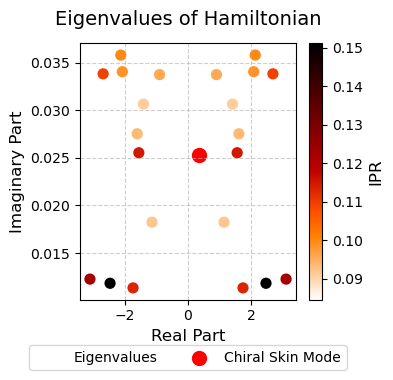

[ 0.35961796+0.02531338j -0.35961796+0.02531338j -0.89958152+0.03372876j
  0.89958152+0.03372876j  1.13958576+0.01823407j -1.13958576+0.01823407j
  1.40905891+0.03063531j -1.40905891+0.03063531j -1.55468033+0.02552528j
  1.55468033+0.02552528j -1.60728601+0.02751701j  1.60728601+0.02751701j
  1.73779855+0.01133848j -1.73779855+0.01133848j  2.07672006+0.03403349j
 -2.07672006+0.03403349j -2.12609262+0.03577945j  2.12609262+0.03577945j
  2.46545999+0.01182347j -2.46545999+0.01182347j  2.68482556+0.03381157j
 -2.68482556+0.03381157j -3.10090687+0.01225972j  3.10090687+0.01225972j]


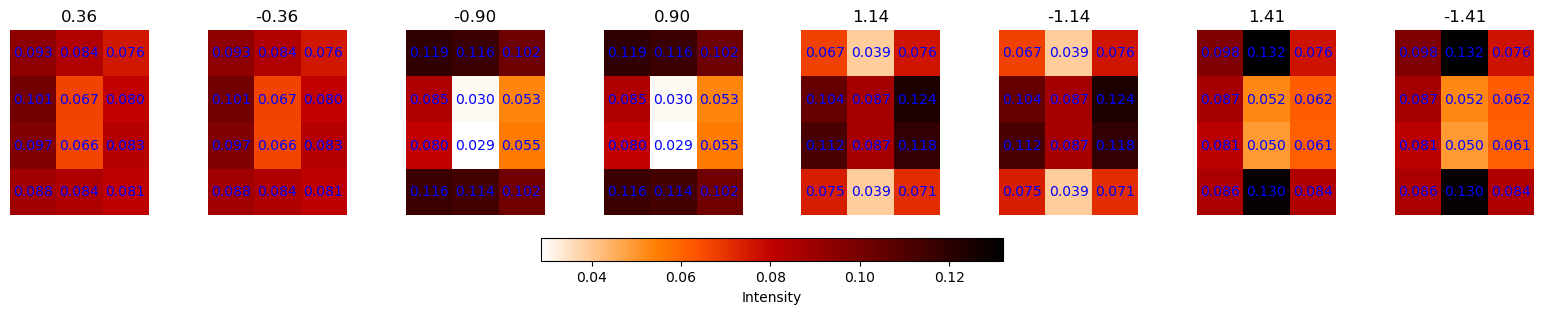

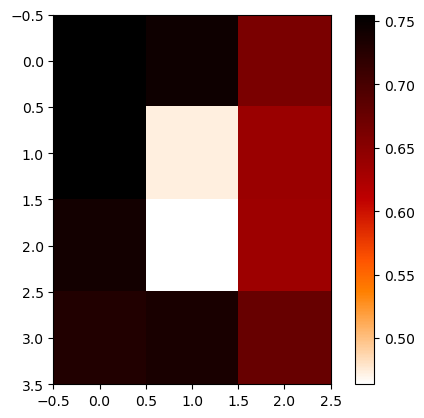

In [181]:
u = -1.5
gamma = -0.1
num_xsite = 3
num_ysite = 4
ham22 = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')
eigval, eigvec = np.linalg.eig(ham22)
eigvec = eigvec[:, np.argsort(np.abs(eigval.real))]
eigval = eigval[np.argsort(np.abs(eigval.real))]
ipr_list = np.zeros(len(eigval))
for i in range(len(eigval)):
    ipr_list[i] = Calculate_IPR(eigvec[:,i])
plt.figure(figsize=(4, 4))
#plt.plot(eigval.real, eigval.imag, 'o', label='Eigenvalues', markersize=8, color='blue')
scatter = plt.scatter(eigval.real, eigval.imag, c=ipr_list, cmap='gist_heat_r', s=50, label='Eigenvalues')

# 突出显示基态
plt.scatter(eigval[0].real, eigval[0].imag, s=100, c='red', marker='o', label='Chiral Skin Mode')

# 添加 colorbar
cbar = plt.colorbar(scatter)
cbar.set_label('IPR', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xlabel('Real Part', fontsize=12)
plt.ylabel('Imaginary Part', fontsize=12)
plt.title('Eigenvalues of Hamiltonian', fontsize=14, y=1.04)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15),fontsize=10,ncol=2)
plt.tight_layout()
plt.show()
print(eigval)

num_eigenstate = 8
fig, ax = plt.subplots(1, num_eigenstate, figsize=(20, 3))
vmin, vmax = 0.2, 0.3  # 统一的颜色范围
# 计算所有数据的最小值和最大值
all_data = []
for i in range(num_eigenstate):
    popu_state = np.abs(eigvec[::2, i]) ** 2 + np.abs(eigvec[1::2, i]) ** 2
    all_data.append(popu_state)
all_data = np.concatenate(all_data)
vmin, vmax = np.min(all_data), np.max(all_data)

color_string = 'gist_heat_r'#'plasma'  # 'seismic'这一个就完全使红蓝的。
# 创建一个 ScalarMappable 对象用于 colorbar
sm = plt.cm.ScalarMappable(cmap=color_string, norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
sm.set_array([])  # 空数组，仅用于 colorbar

total = np.zeros((num_xsite*num_ysite))
for i in range(num_eigenstate):
    popu_state = np.zeros((num_xsite * num_ysite))
    popu_state = np.abs(eigvec[::2, i]) ** 2 + np.abs(eigvec[1::2, i]) ** 2
    total += popu_state
    new_state = popu_state.reshape([num_xsite, num_ysite]).T
    im = ax[i].imshow(new_state, cmap=color_string, vmin=vmin, vmax=vmax)

    # 在每个格子中心添加数值文本
    for x in range(num_xsite):
        for y in range(num_ysite):
            ax[i].text(x,y, f'{new_state[y, x]:.3f}', ha='center', va='center', color='blue', fontsize=10)

    ax[i].axis('off')  # 关闭坐标轴
    ax[i].set_title('%.2f'%eigval[i].real)

# 添加 colorbar
cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.1, pad=0.1)
cbar.set_label('Intensity')

plt.show()

total = total.reshape([num_xsite, num_ysite]).T
im = plt.imshow(total, cmap=color_string)
plt.colorbar()
plt.show()

### 4*4

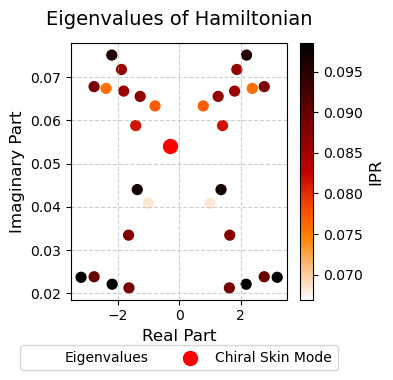

[-0.29719719+0.05417388j  0.29719719+0.05417388j  0.78311682+0.06337735j
 -0.78311682+0.06337735j  1.00024116+0.04082694j -1.00024116+0.04082694j
  1.26709155+0.06558412j -1.26709155+0.06558412j  1.36091158+0.04399042j
 -1.36091158+0.04399042j  1.4110311 +0.05882j    -1.4110311 +0.05882j
 -1.6311292 +0.02120822j  1.6311292 +0.02120822j  1.64438256+0.03342847j
 -1.64438256+0.03342847j  1.80218066+0.06681493j -1.80218066+0.06681493j
  1.87491935+0.07182419j -1.87491935+0.07182419j  2.17680234+0.02205821j
 -2.17680234+0.02205821j  2.18884408+0.07515912j -2.18884408+0.07515912j
  2.37565716+0.06743367j -2.37565716+0.06743367j  2.76401003+0.02378926j
 -2.76401003+0.02378926j  2.76411289+0.06784798j -2.76411289+0.06784798j
  3.18655719+0.02366323j -3.18655719+0.02366323j]


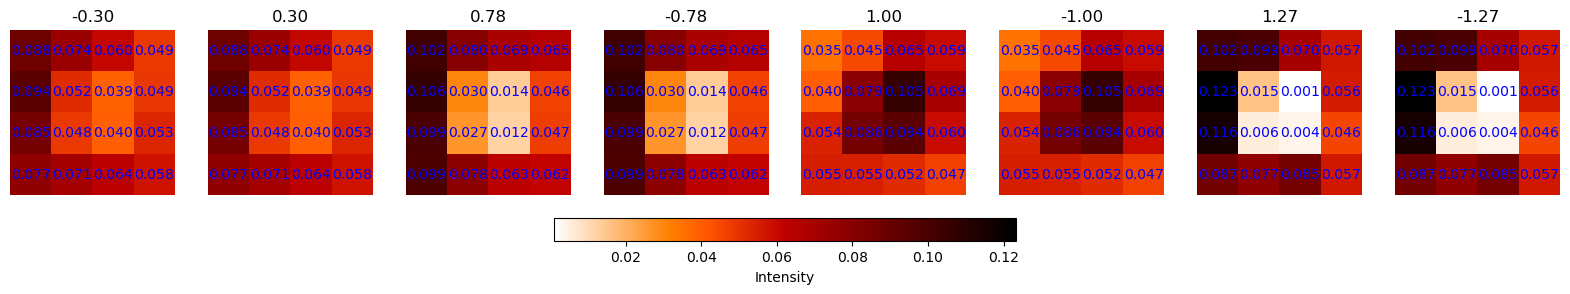

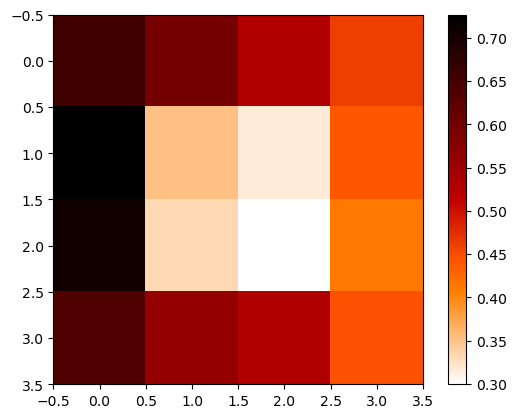

In [67]:
u = -1.5
gamma = -0.2
num_xsite = 4
num_ysite = 4
ham22 = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')
eigval, eigvec = np.linalg.eig(ham22)
eigvec = eigvec[:, np.argsort(np.abs(eigval.real))]
eigval = eigval[np.argsort(np.abs(eigval.real))]
ipr_list = np.zeros(len(eigval))
for i in range(len(eigval)):
    ipr_list[i] = Calculate_IPR(eigvec[:,i])
plt.figure(figsize=(4, 4))
#plt.plot(eigval.real, eigval.imag, 'o', label='Eigenvalues', markersize=8, color='blue')
scatter = plt.scatter(eigval.real, eigval.imag, c=ipr_list, cmap='gist_heat_r', s=50, label='Eigenvalues')

# 突出显示基态
plt.scatter(eigval[0].real, eigval[0].imag, s=100, c='red', marker='o', label='Chiral Skin Mode')

# 添加 colorbar
cbar = plt.colorbar(scatter)
cbar.set_label('IPR', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xlabel('Real Part', fontsize=12)
plt.ylabel('Imaginary Part', fontsize=12)
plt.title('Eigenvalues of Hamiltonian', fontsize=14, y=1.04)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15),fontsize=10,ncol=2)
plt.tight_layout()
plt.show()
print(eigval)

num_eigenstate = 8
fig, ax = plt.subplots(1, num_eigenstate, figsize=(20, 3))
vmin, vmax = 0.2, 0.3  # 统一的颜色范围
# 计算所有数据的最小值和最大值
all_data = []
for i in range(num_eigenstate):
    popu_state = np.abs(eigvec[::2, i]) ** 2 + np.abs(eigvec[1::2, i]) ** 2
    all_data.append(popu_state)
all_data = np.concatenate(all_data)
vmin, vmax = np.min(all_data), np.max(all_data)

color_string = 'gist_heat_r'#'plasma'  # 'seismic'这一个就完全使红蓝的。
# 创建一个 ScalarMappable 对象用于 colorbar
sm = plt.cm.ScalarMappable(cmap=color_string, norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax))
sm.set_array([])  # 空数组，仅用于 colorbar

total = np.zeros((num_xsite*num_ysite))
for i in range(num_eigenstate):
    popu_state = np.zeros((num_xsite * num_ysite))
    popu_state = np.abs(eigvec[::2, i]) ** 2 + np.abs(eigvec[1::2, i]) ** 2
    total += popu_state
    new_state = popu_state.reshape([num_xsite, num_ysite]).T
    im = ax[i].imshow(new_state, cmap=color_string, vmin=vmin, vmax=vmax)

    # 在每个格子中心添加数值文本
    for x in range(num_xsite):
        for y in range(num_ysite):
            ax[i].text(x,y, f'{new_state[y, x]:.3f}', ha='center', va='center', color='blue', fontsize=10)

    ax[i].axis('off')  # 关闭坐标轴
    ax[i].set_title('%.2f'%eigval[i].real)

# 添加 colorbar
cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.1, pad=0.1)
cbar.set_label('Intensity')

plt.show()

total = total.reshape([num_xsite, num_ysite]).T
im = plt.imshow(total, cmap=color_string)
plt.colorbar()
plt.show()

### 20*20

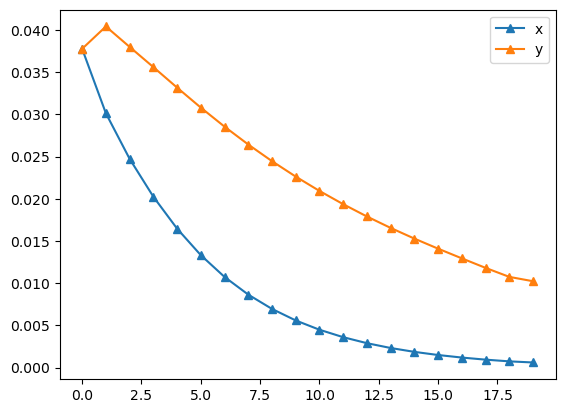

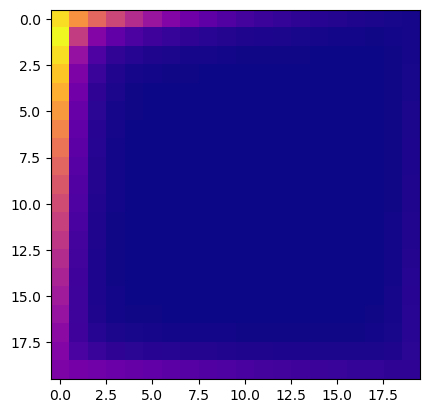

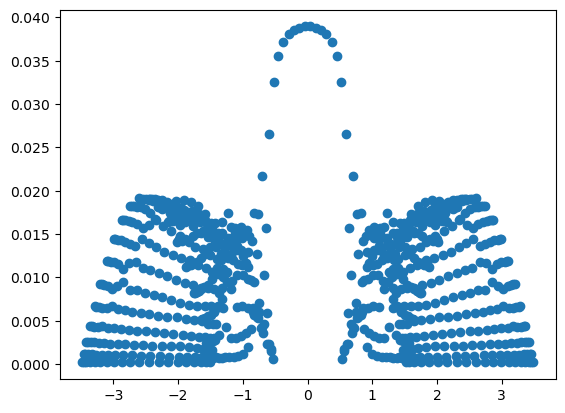

In [63]:
u = -1.5
gamma = -0.2
num_xsite = 20
num_ysite = 20
color_string = 'plasma'
ham22 = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')
eigval, eigvec = np.linalg.eig(ham22)
eigvec = eigvec[:, np.argsort(np.abs(eigval.real))]
eigval = eigval[np.argsort(np.abs(eigval.real))]
ipr_list = np.zeros(len(eigval))
for i in range(len(eigval)):
    ipr_list[i] = Calculate_IPR(eigvec[:,i])

total = np.zeros((num_xsite*num_ysite))
popu_state = np.zeros((num_xsite * num_ysite))
popu_state = np.abs(eigvec[::2, 0]) ** 2 + np.abs(eigvec[1::2, 0]) ** 2
total += popu_state
new_state = popu_state.reshape([num_xsite, num_ysite]).T
plt.plot(new_state[0],'^-',label='x')
plt.plot(new_state[:,0],'^-',label='y')
plt.legend()
#plt.yscale('log')
plt.show()

plt.imshow(new_state, cmap=color_string)#, vmin=vmin, vmax=vmax)
plt.show()

plt.scatter(eigval.real, eigval.imag)
plt.show()

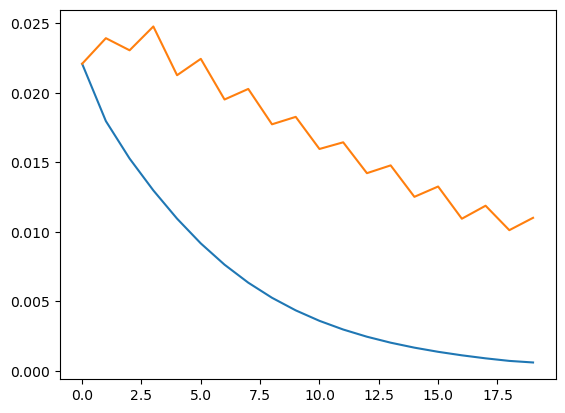

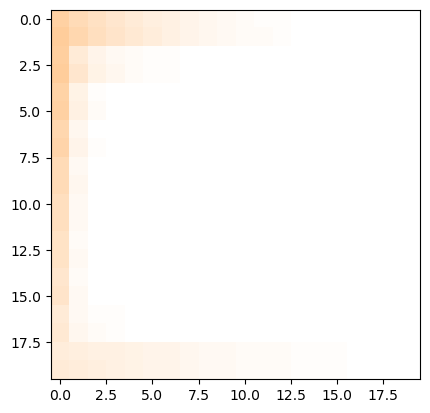

In [205]:
u = -1.5
gamma = -0.2
num_xsite = 20
num_ysite = 10
ham22 = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')
eigval, eigvec = np.linalg.eig(ham22)
eigvec = eigvec[:, np.argsort(np.abs(eigval.real))]
eigval = eigval[np.argsort(np.abs(eigval.real))]
ipr_list = np.zeros(len(eigval))
for i in range(len(eigval)):
    ipr_list[i] = Calculate_IPR(eigvec[:,i])

total = np.zeros((2*num_xsite*num_ysite))
popu_state = np.zeros((2*num_xsite * num_ysite))
popu_state = np.abs(eigvec[:,0])**2#np.abs(eigvec[::2, 0]) ** 2 + np.abs(eigvec[1::2, 0]) ** 2
total += popu_state
new_state = popu_state.reshape([num_xsite, 2*num_ysite]).T
plt.plot(new_state[0])
plt.plot(new_state[:,0])
#plt.yscale('log')
plt.show()

plt.imshow(new_state, cmap=color_string, vmin=vmin, vmax=vmax)
plt.show()

In [23]:
# 1. CZ门和CNOT门的关系。2. 测量的序参量。
h = np.array([[1,1],[1,-1]])/np.sqrt(2)
print(np.dot(np.conj(h.T),h))

h = np.array([[1,1],[1,-1]]) / np.sqrt(2)
iden = np.identity(2)
CZ = np.diag([1,1,1,-1])
print('CZ:', CZ)
print("CNOT:", np.dot(np.kron(iden,h), np.dot(CZ, np.kron(iden,h))))

CNOT1 = np.array([[1,0,0,0],[0,0,0,1],[0,0,1,0],[0,1,0,0]])
CNOT2 = np.array([[1,0,0,0],[0,1,0,0],[0,0,0,1],[0,0,1,0]])
print(CNOT1, CNOT2, np.dot(CNOT1, CNOT2))

a = np.random.random(100)
S_Q = np.sum(-np.log((a+1)/2)/np.log(2)) / len(a)
S_proxy = -np.log((np.average(a)+1)/2)/np.log(2)
print('S_Q>S_proy', S_Q, S_proxy)



[[1. 0.]
 [0. 1.]]
CZ: [[ 1  0  0  0]
 [ 0  1  0  0]
 [ 0  0  1  0]
 [ 0  0  0 -1]]
CNOT: [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 0. 1.]
 [0. 0. 1. 0.]]
[[1 0 0 0]
 [0 0 0 1]
 [0 0 1 0]
 [0 1 0 0]] [[1 0 0 0]
 [0 1 0 0]
 [0 0 0 1]
 [0 0 1 0]] [[1 0 0 0]
 [0 0 1 0]
 [0 0 0 1]
 [0 1 0 0]]
S_Q>S_proy 0.45796968202010513 0.4286844039619826


### Qiskit量子线路

In [351]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Operator
from scipy.linalg import expm
import numpy as np
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Operator, Statevector

def simulate_H_evolution(t):
    # 构建哈密顿量矩阵 (8x8)
    H = np.zeros((8, 8))
    H[3, 5] = 1  # |011><101|
    H[5, 3] = 1  # Hermitian conjugate
    
    # 计算时间演化算符
    U = expm(-1j * H * t)
    
    # 创建量子电路并应用演化算符
    qc = QuantumCircuit(3)
    qc.unitary(Operator(U), [0, 1, 2], label=f'exp(-iHt), t={t}')
    
    # 初始化到 |011> 态（假设 q0 是最低位）
    init_qc = QuantumCircuit(3)
    init_qc.x([0, 1])  # q0=1, q1=1, q2=0 -> |011⟩
    
    # 组合初始化和演化
    full_circuit = init_qc.compose(qc)
    #full_circuit.measure_all()
    
    print(full_circuit)

    # 运行模拟
    # simulator = AerSimulator()
    # compiled = transpile(full_circuit, simulator)
    # result = simulator.run(compiled, shots=1024).result()
    # counts = result.get_counts()
    state = Statevector(full_circuit)
    print(state)
    return 0

from qiskit.quantum_info import Operator, Statevector
def get_wavefunction(t):
    # 构建哈密顿量矩阵 (8x8)
    u = -1.5 
    H0 = np.zeros((4,4), dtype=np.complex128)
    H0[3, 3] = u
    U0 = expm(-1j * H0 * t)

    # H = np.zeros((8, 8), dtype=np.complex128)
    # H[3, 5] = 1  # |011><101|（注意量子位顺序）
    # H[5, 3] = 1  # 厄米共轭项
    
    # 计算时间演化算符 U = e^(-iHt)
    # U = expm(-1j * H * t)
    
    # 创建量子电路并应用演化
    qc = QuantumCircuit(8)
    for i in range(4):
        for j in range(4, 8):
            #print(i,j)
            qc.unitary(Operator(U0), [i, j], label='U0')
    
    
    # 初始化到 |011⟩（q0=1, q1=1, q2=0）
    init_qc = QuantumCircuit(8)
    #init_qc.x([0, 1])
    
    # 合并初始化电路和演化电路
    full_circuit = init_qc.compose(qc)
    #print(full_circuit)
    # 直接通过 Statevector 计算波函数
    state = Statevector(full_circuit)
    return state

# # 示例：取 t=π 并打印结果
print(simulate_H_evolution(np.pi/4))


# 获取 t=π 时的波函数
wavefunction = get_wavefunction(np.pi)

# 输出波函数信息
print("Final Statevector:")
#print(wavefunction.data)  # 复数数组表示各基态振幅


print((1<<0)+(1<<(4)))


     ┌───┐┌──────────────────────────────────┐
q_0: ┤ X ├┤0                                 ├
     ├───┤│                                  │
q_1: ┤ X ├┤1 exp(-iHt), t=0.7853981633974483 ├
     └───┘│                                  │
q_2: ─────┤2                                 ├
          └──────────────────────────────────┘
Statevector([0.        +0.j        , 0.        +0.j        ,
             0.        +0.j        , 0.70710678+0.j        ,
             0.        +0.j        , 0.        -0.70710678j,
             0.        +0.j        , 0.        +0.j        ],
            dims=(2, 2, 2))
0
Final Statevector:
17


In [358]:
u=-1.5
gamma = 0.2
num_xsite = 2
num_ysite = 2
ham1 = RealHam_QWZ_Dissapation(u, 0, gamma, num_xsite, num_ysite, boundary='open',B=0)
ham1 = np.imag(ham1)
ham2 = RealHam_QWZ_Dissapation(u, 1, 0, num_xsite, num_ysite, boundary='open')
print(ham1, ham2)
print(np.linalg.norm(np.dot(ham1,ham2)-np.dot(ham2,ham1)))

[[-0.2  0.   0.   0.   0.   0.   0.   0. ]
 [ 0.  -0.2  0.   0.   0.   0.   0.   0. ]
 [ 0.   0.   0.   0.   0.   0.   0.   0. ]
 [ 0.   0.   0.   0.   0.   0.   0.   0. ]
 [ 0.   0.   0.   0.  -0.2  0.   0.   0. ]
 [ 0.   0.   0.   0.   0.  -0.2  0.   0. ]
 [ 0.   0.   0.   0.   0.   0.   0.   0. ]
 [ 0.   0.   0.   0.   0.   0.   0.   0. ]] [[-1.5+0.j   0. +0.j   0.5+0.j  -0.5+0.j   0.5+0.j  -0. -0.5j  0. +0.j
   0. +0.j ]
 [ 0. +0.j   1.5+0.j   0.5+0.j  -0.5+0.j  -0. -0.5j -0.5+0.j   0. +0.j
   0. +0.j ]
 [ 0.5+0.j   0.5+0.j  -1.5+0.j   0. +0.j   0. +0.j   0. +0.j   0.5+0.j
  -0. -0.5j]
 [-0.5+0.j  -0.5+0.j   0. +0.j   1.5+0.j   0. +0.j   0. +0.j  -0. -0.5j
  -0.5+0.j ]
 [ 0.5+0.j   0. +0.5j  0. +0.j   0. +0.j  -1.5+0.j   0. +0.j   0.5+0.j
  -0.5+0.j ]
 [ 0. +0.5j -0.5+0.j   0. +0.j   0. +0.j   0. +0.j   1.5+0.j   0.5+0.j
  -0.5+0.j ]
 [ 0. +0.j   0. +0.j   0.5+0.j   0. +0.5j  0.5+0.j   0.5+0.j  -1.5+0.j
   0. +0.j ]
 [ 0. +0.j   0. +0.j   0. +0.5j -0.5+0.j  -0.5+0.j  -0.5+0.j   0. 

In [415]:
qc = QuantumCircuit(4)  # 4 量子比特，1 经典比特用于存储测量结果

# 初始化 q3 为 |1⟩
qc.h([0,2])
qc.cx(0,1)
qc.cx(2,3)
qc.x([1,3])
qc.cx(0,2)
qc.cx(2,1)
qc.cx(1,3)
#qc.cx(3,0)
qc.ccx(0,1,3)
qc.cx(3,0)
qc.cx(3,1)
qc.cx(3,2)
qc.reset(0)#z这一步可直接投影到0.

# # 对 q0, q1, q2 施加 Hadamard 门
# qc.h(0)
# qc.h(1)
# qc.h(2)

# # 条件翻转：将 |1⟩ 从 q3 转移到其他比特
# qc.ccx(0, 3, 1)  # 当 q0=1 时，翻转 q3 和 q0
# qc.ccx(1, 3, 2)  # 当 q1=1 时，翻转 q3 和 q1
# qc.ccx(2, 3, 0)  # 当 q2=1 时，翻转 q3 和 q2

print(qc)

# # 对 q0 进行投影测量
# qc.measure(0, 0)  # 测量 q0，结果存储到经典比特 0

state = Statevector(qc)
print(state)

# 这个reset首先需要将量子态塌缩，不管测量结果为什么，都需要将它制为0态。
qc = QuantumCircuit(2)
qc.h(0)
qc.cx(0,1)
qc.reset(0)

state = Statevector(qc)
print(state)


# 
print('-----Run from an initial state:-----')
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# 定义一个初态，比如 Bell 态 |ψ⟩ = (|00⟩ + |11⟩)/√2
initial_state = Statevector([1/2**0.5, 0, 0, 1/2**0.5])

# 创建量子线路
qc = QuantumCircuit(2)
qc.initialize(initial_state, [0, 1])  # 设定初态

# 进行演化，例如应用 Hadamard 门
qc.h(0)
qc.cx(0, 1)
state = Statevector(qc)
print(state)

     ┌───┐                              ┌───┐          
q_0: ┤ H ├──■─────────■──────────────■──┤ X ├─|0>──────
     └───┘┌─┴─┐┌───┐  │  ┌───┐       │  └─┬─┘┌───┐     
q_1: ─────┤ X ├┤ X ├──┼──┤ X ├──■────■────┼──┤ X ├─────
     ┌───┐└───┘└───┘┌─┴─┐└─┬─┘  │    │    │  └─┬─┘┌───┐
q_2: ┤ H ├──■───────┤ X ├──■────┼────┼────┼────┼──┤ X ├
     └───┘┌─┴─┐┌───┐└───┘     ┌─┴─┐┌─┴─┐  │    │  └─┬─┘
q_3: ─────┤ X ├┤ X ├──────────┤ X ├┤ X ├──■────■────■──
          └───┘└───┘          └───┘└───┘               
Statevector([0.        +0.j, 0.        +0.j, 0.57735027+0.j,
             0.        +0.j, 0.57735027+0.j, 0.        +0.j,
             0.        +0.j, 0.        +0.j, 0.57735027+0.j,
             0.        +0.j, 0.        +0.j, 0.        +0.j,
             0.        +0.j, 0.        +0.j, 0.        +0.j,
             0.        +0.j],
            dims=(2, 2, 2, 2))
Statevector([1.+0.j, 0.+0.j, 0.+0.j, 0.+0.j],
            dims=(2, 2))
-----Run from an initial state:-----
Statevector([ 0.5+0.j,

In [19]:
def qr_haar(N):
    """
        Generate a Haar-random matrix using the QR decomposition.

    References:
        <How to generate random matrices from the classical compact groups>
    Parameters
    ----------
    N : the dimension of the matrix

    Returns
    -------

    """
    # Step 1
    A, B = np.random.normal(size=(N, N)), np.random.normal(size=(N, N))
    Z = A + 1j * B

    # Step 2
    from numpy.linalg import qr
    Q, R = qr(Z)

    # Step 3
    Lambda = np.diag([R[i, i] / np.abs(R[i, i]) for i in range(N)])

    # Step 4
    return Q@Lambda

# 分解两比特门
# U = np.identity(4)
# U[1:3,1:3] = qr_haar(2)
from qiskit.quantum_info import TwoQubitBasisDecomposer
from qiskit.circuit.library import CXGate

# 定义一个 4x4 的双量子比特幺正矩阵
unitary_matrix = np.array([[1, 0, 0, 0],
                           [0, 1, 0, 0],
                           [0, 0, 0, 1],
                           [0, 0, 1, 0]])  # 示例：CNOT 门

# 创建分解器
decomposer = TwoQubitBasisDecomposer(CXGate())

# 分解幺正矩阵
decomposed_circuit = decomposer(unitary_matrix)

# 打印分解后的线路
print(decomposed_circuit.draw())


# 我也动用了Qiskit进行了分解，也需要三个CZ门，但是给不出解析表达式。我的分解方法需要四个，但是需要公式。
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import random_unitary
#from qiskit.synthesis import TwoQubitBasisDecomposer
from qiskit.circuit.library import CZGate

# 定义量子门 U
U = np.identity(4, dtype='complex')
U[1:3, 1:3] = qr_haar(2)#random_unitary(2).data  # 使用随机幺正矩阵填充 U[1:3, 1:3]

# 打印 U
print("目标幺正矩阵 U：")
print(U)

# 创建 CZ 门分解器
decomposer = TwoQubitBasisDecomposer(CZGate())

# 分解 U 为单量子比特门和 CZ 门的组合
decomposed_circuit = decomposer(U)

# 打印分解后的线路
print("\n分解后的量子线路：")
# print(decomposed_circuit.draw(output='mpl'))
print(decomposed_circuit.draw())

# 计算分解后线路的幺正矩阵
decomposed_matrix = Operator(decomposed_circuit).data

# 打印分解后的矩阵
print("\n分解后的幺正矩阵：")
print(decomposed_matrix)

# 验证两个矩阵是否相等（允许一定的数值误差）
if np.allclose(U, decomposed_matrix, atol=1e-7):
    print("\n验证结果：分解后的线路与原始矩阵等价！")
else:
    print("\n验证结果：分解后的线路与原始矩阵不等价！")


global phase: 2π
        ┌────────────────┐      ┌────────────────┐
q861_0: ┤ U3(π/2,π/4,-π) ├──■───┤ U3(π/2,0,3π/4) ├
        ├───────────────┬┘┌─┴─┐┌┴────────────────┤
q861_1: ┤ U3(π/2,0,π/4) ├─┤ X ├┤ U3(π/2,3π/4,-π) ├
        └───────────────┘ └───┘└─────────────────┘
目标幺正矩阵 U：
[[ 1.        +0.j          0.        +0.j          0.        +0.j
   0.        +0.j        ]
 [ 0.        +0.j         -0.3096094 -0.50341026j -0.47640995+0.65096367j
   0.        +0.j        ]
 [ 0.        +0.j         -0.3024336 +0.7478329j  -0.5909958 +0.00195739j
   0.        +0.j        ]
 [ 0.        +0.j          0.        +0.j          0.        +0.j
   1.        +0.j        ]]

分解后的量子线路：
global phase: 5.6211
         ┌────────────────────┐    ┌─────────────────────┐   »
q862_0: ─┤ U3(π/2,π/2,2.6469) ├──■─┤ U3(0.9385,-π/2,π/2) ├─■─»
        ┌┴────────────────────┴┐ │ └┬───────────────────┬┘ │ »
q862_1: ┤ U3(π/2,-π/2,0.68849) ├─■──┤ U3(π/2,-2.5093,0) ├──■─»
        └──────────────────────┘    └────────

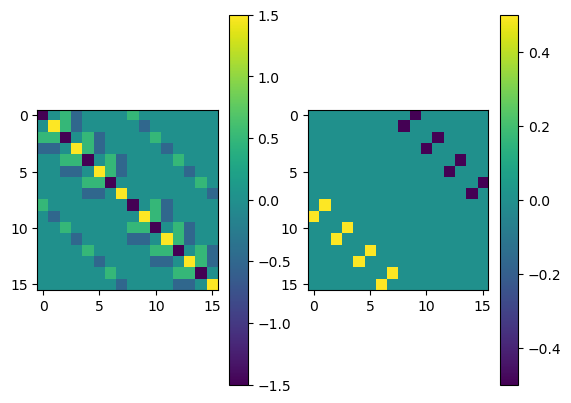

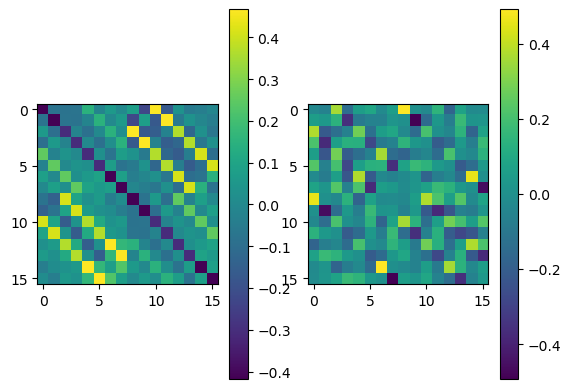


分解后的量子线路：
优化后门数量: OrderedDict([('u3', 151), ('cx', 99), ('swap', 52)])
优化后线路深度: 233

分解后的幺正矩阵形状： (16, 16)

验证结果：分解后的线路与原始矩阵不等价！
Is UM unitary? True
     
q_0: 
     
q_1: 
     
q_2: 
     
q_3: 
     
q_4: 
     

分解后的量子线路：
     
q_0: 
     
q_1: 
     
q_2: 
     
q_3: 
     
q_4: 
     

分解后的幺正矩阵形状： (32, 32)

验证结果：分解后的线路与原始矩阵等价！
     
q_0: 
     
q_1: 
     
q_2: 
     


In [59]:
#分解演化
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Operator
from scipy.linalg import expm
import numpy as np
import matplotlib.pyplot as plt
u = -1.5
gamma = -0.
num_xsite = 2
num_ysite = 4
ham22 = RealHam_QWZ_Dissapation(u, 1, gamma, num_xsite, num_ysite, boundary='open')

fig, ax = plt.subplots(1, 2)
ax0 = ax[0].imshow(ham22.real)
ax1 = ax[1].imshow(ham22.imag)
fig.colorbar(ax0, ax=ax[0])
fig.colorbar(ax1, ax=ax[1])
plt.show()

U = expm(-1j*ham22*1.85) # 1.85, 2

fig, ax = plt.subplots(1, 2)
ax0 = ax[0].imshow(U.real)
ax1 = ax[1].imshow(U.imag)
fig.colorbar(ax0, ax=ax[0])
fig.colorbar(ax1, ax=ax[1])
plt.show()

# 创建量子线路并应用 U
qc = QuantumCircuit(4)  # 4 量子比特线路
qc.unitary(U, [0, 1, 2, 3], label='U')  # 将 U 作用在 q0, q1, q2, q3 上

# 使用 transpile 分解为单量子比特门和 CZ 门。
transpiled_qc = transpile(qc, routing_method='sabre', basis_gates=['u3', 'cx', 'rx', 'swap', 'iswap', 'crx', 'cry', 'crz', 'rxx', 'ryy', 'rzz', 'fsim', 'xx'],coupling_map=[[0, 1], [2,3], [1, 2], [1,0], [3,2], [2,1]],optimization_level=3)
# transpiled_qc = transpile(qc, unitary_synthesis_method='sk', basis_gates=['u3', 'cx', 'ccx'], optimization_level=2) # coupling_map=[[0, 1], [2,3], [1, 2]], # basis_gates=['u3', 'cx', 'rx', 'swap', 'iswap', 'crx', 'cry', 'crz', 'rxx', 'ryy', 'rzz', 'fsim', 'xx'], 

# 打印分解后的线路
print("\n分解后的量子线路：")
# 验证保真度
print(f"优化后门数量: {transpiled_qc.count_ops()}")
print(f"优化后线路深度: {transpiled_qc.depth()}")
# circuit_text = transpiled_qc.draw(output='text').single_string() # ,fold=80
# # print(transpiled_qc.draw())
# print(type(circuit_text))
# with open('decomposed_circuit.txt', 'w') as f:
#     f.write(circuit_text)

# # 将量子线路绘制为图像
circuit_image = transpiled_qc.draw(output='mpl',fold=100)
# 保存为 PNG 文件
circuit_image.savefig('decomposed_circuit.png')

# 计算分解后线路的幺正矩阵
decomposed_matrix = Operator(transpiled_qc).data

# 打印分解后的矩阵形状
print("\n分解后的幺正矩阵形状：", decomposed_matrix.shape)

# 验证两个矩阵是否相等（允许一定的数值误差）
if np.allclose(U, decomposed_matrix, atol=1e-7):
    print("\n验证结果：分解后的线路与原始矩阵等价！")
else:
    print("\n验证结果：分解后的线路与原始矩阵不等价！")



# decompose measurement unitary. 不能分解？但是这一步可以通过四体控制门来实现！！多个control门，比较简单。
UM = np.identity(2**5, dtype=np.complex128)
alpha = np.exp(-gamma*1)
beta = np.sqrt(1-alpha**2)
# 耗散的 # 这个其实区分1-4的比特。
# UM[:2,:2] = np.array([[alpha, beta],[-beta,alpha]]) # 0000 0
# UM[2:4,2:4] = np.array([[alpha, beta],[-beta,alpha]]) # 0001 0
# UM[16:18,16:18] = np.array([[alpha, beta],[-beta,alpha]]) # 1000 0
# UM[18:20,18:20] = np.array([[alpha, beta],[-beta,alpha]]) # 1001 0
# 增益的
UM[4:6,4:6] = np.array([[alpha, beta],[-beta,alpha]], dtype=np.complex128) # 0010 0
UM[6:8,6:8] = np.array([[alpha, beta],[-beta,alpha]], dtype=np.complex128) # 0011 0
UM[8:10,8:10] = np.array([[alpha, beta],[-beta,alpha]], dtype=np.complex128) # 0100 0
UM[10:12,10:12] = np.array([[alpha, beta],[-beta,alpha]], dtype=np.complex128) # 0101 0
UM[12:14,12:14] = np.array([[alpha, beta],[-beta,alpha]], dtype=np.complex128) # 0110 0
UM[14:16,14:16] = np.array([[alpha, beta],[-beta,alpha]], dtype=np.complex128) # 0111 0
UM[20:22,20:22] = np.array([[alpha, beta],[-beta,alpha]], dtype=np.complex128) # 1010 0
UM[22:24,22:24] = np.array([[alpha, beta],[-beta,alpha]], dtype=np.complex128) # 1011 0
UM[24:26,24:26] = np.array([[alpha, beta],[-beta,alpha]], dtype=np.complex128) # 1100 0
UM[26:28,26:28] = np.array([[alpha, beta],[-beta,alpha]], dtype=np.complex128) # 1101 0
UM[28:30,28:30] = np.array([[alpha, beta],[-beta,alpha]], dtype=np.complex128) # 1110 0
UM[30:32,30:32] = np.array([[alpha, beta],[-beta,alpha]], dtype=np.complex128) 
# 1111 0
is_unitary = np.allclose(np.eye(len(UM)), UM @ UM.conj().T)
print("Is UM unitary?", is_unitary)
qc = QuantumCircuit(5)  # 4 量子比特线路
qc.unitary(UM, [4, 0, 1, 2, 3], label='UM')  # 将 U 作用在 q0, q1, q2, q3 上

# 使用 transpile 分解为单量子比特门和 CZ 门
transpiled_qc = transpile(qc, basis_gates=['u3', 'cx'], optimization_level=3)
print(transpiled_qc)

# 打印分解后的线路
print("\n分解后的量子线路：")
circuit_text = transpiled_qc.draw(output='text').single_string() # ,fold=80
# print(transpiled_qc.draw())
print(circuit_text)
with open('decomposed_circuit.txt', 'w') as f:
    f.write(circuit_text)

# # 将量子线路绘制为图像
circuit_image = transpiled_qc.draw(output='mpl')
# 保存为 PNG 文件
circuit_image.savefig('decomposed_measurement_circuit.png')

# 计算分解后线路的幺正矩阵
decomposed_matrix = Operator(transpiled_qc).data

# 打印分解后的矩阵形状
print("\n分解后的幺正矩阵形状：", decomposed_matrix.shape)

# 验证两个矩阵是否相等（允许一定的数值误差）
if np.allclose(UM, decomposed_matrix, atol=1e-7):
    print("\n验证结果：分解后的线路与原始矩阵等价！")
else:
    print("\n验证结果：分解后的线路与原始矩阵不等价！")


from qiskit import QuantumCircuit

qc = QuantumCircuit(3)
# qc.ccx(0.1, 0, 1, 2)  # 原始 Toffoli 门
transpiled_qc = transpile(qc, routing_method='sabre', basis_gates=['rx', 'ry', 'cx'], optimization_level=3) # , 'ccx'
print(transpiled_qc)


0
8


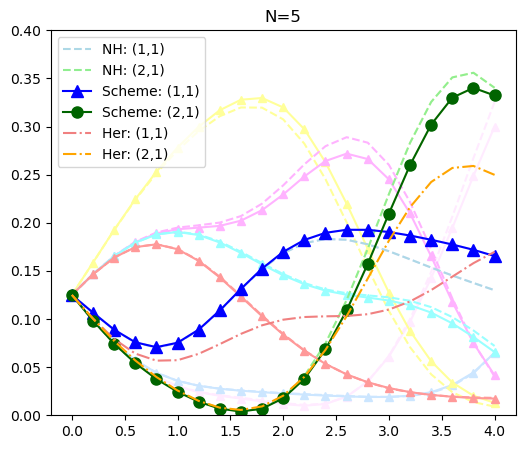

Eigenstate: [ 0.02336303+0.19380577j  0.02926302+0.17408922j -0.05946466+0.36008776j
 -0.04774957+0.21221799j -0.0542078 +0.3050494j  -0.02206231+0.17297533j
  0.01900653+0.17966597j  0.00021463+0.12351948j  0.02336303-0.19380577j
  0.02926302-0.17408922j -0.05946466-0.36008776j -0.04774957-0.21221799j
 -0.0542078 -0.3050494j  -0.02206231-0.17297533j  0.01900653-0.17966597j
  0.00021463-0.12351948j]
population: [0.1840519  0.33155397 0.21808214 0.03742152 0.02880277 0.09449598
 0.08713121 0.0184605 ]


In [267]:
gamma = 0.2
u = -1.5
num_xsite = 2
num_ysite = 4
num_slice = 5
ham22 = RealHam_QWZ_Dissapation(u, 1, 0, num_xsite, num_ysite, boundary='open')

for delta_y in range(num_xsite):
    row = 2 * (delta_y * num_ysite + 0)
    print(row)
# 耗散
def EvoFun(DELTA_T, depth_t):
    #DELTA_T = 3.7/2
    U = np.kron(expm(-1j*ham22*DELTA_T),np.identity(2))
    #UM = np.diag([1,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0]) * np.exp(-gamma*DELTA_T) # 0000,0001, 1000,1001
    #print(UM.shape,UM)
    #print(bin(8))
    UM = np.identity(2**5, dtype=np.complex128)
    alpha = np.exp(-gamma*DELTA_T)
    beta = np.sqrt(1-alpha**2)
    # 耗散的 # 这个其实区分1-4的比特。
    # UM[:2,:2] = np.array([[alpha, beta],[-beta,alpha]]) # 0000 0
    # UM[2:4,2:4] = np.array([[alpha, beta],[-beta,alpha]]) # 0001 0
    # UM[16:18,16:18] = np.array([[alpha, beta],[-beta,alpha]]) # 1000 0
    # UM[18:20,18:20] = np.array([[alpha, beta],[-beta,alpha]]) # 1001 0
    # 增益的
    UM[4:6,4:6] = np.array([[alpha, beta],[-beta,alpha]], dtype=np.complex128) # 0010 0
    UM[6:8,6:8] = np.array([[alpha, beta],[-beta,alpha]], dtype=np.complex128) # 0011 0
    UM[8:10,8:10] = np.array([[alpha, beta],[-beta,alpha]], dtype=np.complex128) # 0100 0
    UM[10:12,10:12] = np.array([[alpha, beta],[-beta,alpha]], dtype=np.complex128) # 0101 0
    UM[12:14,12:14] = np.array([[alpha, beta],[-beta,alpha]], dtype=np.complex128) # 0110 0
    UM[14:16,14:16] = np.array([[alpha, beta],[-beta,alpha]], dtype=np.complex128) # 0111 0
    UM[20:22,20:22] = np.array([[alpha, beta],[-beta,alpha]], dtype=np.complex128) # 1010 0
    UM[22:24,22:24] = np.array([[alpha, beta],[-beta,alpha]], dtype=np.complex128) # 1011 0
    UM[24:26,24:26] = np.array([[alpha, beta],[-beta,alpha]], dtype=np.complex128) # 1100 0
    UM[26:28,26:28] = np.array([[alpha, beta],[-beta,alpha]], dtype=np.complex128) # 1101 0
    UM[28:30,28:30] = np.array([[alpha, beta],[-beta,alpha]], dtype=np.complex128) # 1110 0
    UM[30:32,30:32] = np.array([[alpha, beta],[-beta,alpha]], dtype=np.complex128) # 1111 0

    from qiskit.quantum_info import Operator, Statevector
    # defined the circuit and run it.
    full_circuit = QuantumCircuit(5)
    full_circuit.unitary(Operator(U), [4,0,1,2,3], label='U') # 为什么这才是正确顺序？
    full_circuit.unitary(Operator(UM), [4,0,1,2,3], label='UM')
    #print('-----', np.diagonal(Operator(full_circuit).data))

    qc = QuantumCircuit(4)
    # qc_m.unitary(Operator(UM), [8,4,1,0], label='U2')
    # qc_m.unitary(Operator(UM), [9,4,3,2], label='U2')
    qc.h([0,1,2,3])
    state = Statevector(qc)

    for i in range(depth_t): # divide t into how many pieces. 
        # the second
        qc = QuantumCircuit(5)
        qc.initialize(state, [0,1,2,3])
        qc=qc.compose(full_circuit)
        state = Statevector(qc)
        state = np.array(state)
        state = state[:2**4]
        state = state / np.sqrt(np.sum(np.abs(state)**2))
    popu_state = np.abs(state[::2])**2 + np.abs(state[1::2])**2
    return popu_state

colors = [
    '#e6e6ff',  # 浅蓝色
    '#ffffcc',  # 浅黄色
    '#ffebff',  # 浅粉色
    '#cce6ff',  # 更浅的蓝色
    '#ffff99',  # 浅金黄色
    '#ffb3ff',  # 浅紫色
    '#99ffff',  # 浅青色
    '#ff9999'   # 浅红色
]

# 计算非厄米的结果
ham22_Non= RealHam_QWZ_Dissapation(u, 1, -gamma, num_xsite, num_ysite, boundary='open')
t_list = np.linspace(0, 4, 21)
popu_list = np.zeros((8,len(t_list)))
popu_Non = np.zeros((8,len(t_list)))
popu_Her = np.zeros((8,len(t_list)))
#prob_list = np.zeros(len(t_list))
for i in range(len(t_list)):
    # non hermitian 
    evo_Non = expm(-1j*ham22_Non*t_list[i])
    final_state = np.dot(evo_Non, np.ones(16)/4)
    final_state = final_state / np.sqrt(np.sum(np.abs(final_state)**2))
    popu_Non[:, i] = np.abs(final_state[::2])**2 + np.abs(final_state[1::2])**2
    # hermitian 
    evo_Non = expm(-1j*ham22*t_list[i])
    final_state = np.dot(evo_Non, np.ones(16)/4)
    final_state = final_state / np.sqrt(np.sum(np.abs(final_state)**2))
    popu_Her[:, i] = np.abs(final_state[::2])**2 + np.abs(final_state[1::2])**2

for i in range(len(t_list)):
    popu_list[:,i] = EvoFun(t_list[i]/num_slice,num_slice)
order_string = [0,4,1,5,2,6,3,7]
#order_string = np.arange(0,8)

fig, ax = plt.subplots(1, 1, figsize=(6, 5))
for i in range(8):
    plt.plot(t_list, popu_list[i], '^-', color=colors[i]) # ,color=colors[order_string[i]]
    plt.plot(t_list, popu_Non[i], '--', color=colors[i])
# plt.plot(t_list, popu_Non[0],'--',color='k',label='(%d,%d)'%(1,1))
# plt.plot(t_list, popu_Non[1],'--',color='lime',label='(%d,%d)'%(2,1))
# plt.plot(t_list, popu_list[0],'^',color='k',label='(%d,%d)'%(1,1))
# plt.plot(t_list, popu_list[1],'o',color='lime',label='(%d,%d)'%(2,1))
# plt.plot(t_list, popu_Her[0],'-',color='k',label='(%d,%d)'%(1,1))
# plt.plot(t_list, popu_Her[1],'-',color='lime',label='(%d,%d)'%(2,1))
# 绘制第一组数据（popu_Non）：使用虚线，颜色较浅
plt.plot(t_list, popu_Non[0], '--', color='lightblue', label='NH: (%d,%d)' % (1, 1))
plt.plot(t_list, popu_Non[1], '--', color='lightgreen', label='NH: (%d,%d)' % (2, 1))
# 绘制中间组数据（popu_list）：使用实线 + 标记，颜色较深
plt.plot(t_list, popu_list[0], '-^', color='blue', markersize=8, label='Scheme: (%d,%d)' % (1, 1))
plt.plot(t_list, popu_list[1], '-o', color='darkgreen', markersize=8, label='Scheme: (%d,%d)' % (2, 1))
# 绘制第三组数据（popu_Her）：使用点划线，颜色较浅
plt.plot(t_list, popu_Her[0], '-.', color='lightcoral', label='Her: (%d,%d)' % (1, 1))
plt.plot(t_list, popu_Her[1], '-.', color='orange', label='Her: (%d,%d)' % (2, 1))
plt.title(f'N={num_slice}')
# plt.vlines(3.7, ymin=0, ymax=0.4,linestyles='--')
plt.legend()
plt.ylim(ymin=0, ymax=0.4)
# 与非厄米对应很好！
#plt.plot(t_list, [2*(np.exp(gamma*x)/np.sqrt(4*np.exp(2*gamma*x)+12))**2 for x in t_list])
#plt.plot(t_list, [(np.exp(gamma*x)/np.sqrt(np.exp(2*gamma*x)+1))**2 for x in t_list])
plt.show()

print('Eigenstate:',state)
print('population:',EvoFun(3.7/4,4))

In [19]:
gamma = 0.
u = -1.5
num_xsite = 2
num_ysite = 2
ham22 = RealHam_QWZ_Dissapation(u, 1, -gamma, num_xsite, num_ysite, boundary='open')
print(ham22)
#np.savez('NH_Hamiltonian.npz', Hamiltonian=ham22)
# with np.load('NH_Hamiltonian.npz') as files:
#     ham = files['Hamiltonian']
#     print(ham, np.diag(ham))
# if np.allclose(ham22, ham, atol=1e-7):
#     print("\n等价")
# else:
#     print("\n不等价！")


[[-1.5+0.j   0. +0.j   0.5+0.j  -0.5+0.j   0.5+0.j  -0. -0.5j  0. +0.j
   0. +0.j ]
 [ 0. +0.j   1.5+0.j   0.5+0.j  -0.5+0.j  -0. -0.5j -0.5+0.j   0. +0.j
   0. +0.j ]
 [ 0.5+0.j   0.5+0.j  -1.5+0.j   0. +0.j   0. +0.j   0. +0.j   0.5+0.j
  -0. -0.5j]
 [-0.5+0.j  -0.5+0.j   0. +0.j   1.5+0.j   0. +0.j   0. +0.j  -0. -0.5j
  -0.5+0.j ]
 [ 0.5+0.j   0. +0.5j  0. +0.j   0. +0.j  -1.5+0.j   0. +0.j   0.5+0.j
  -0.5+0.j ]
 [ 0. +0.5j -0.5+0.j   0. +0.j   0. +0.j   0. +0.j   1.5+0.j   0.5+0.j
  -0.5+0.j ]
 [ 0. +0.j   0. +0.j   0.5+0.j   0. +0.5j  0.5+0.j   0.5+0.j  -1.5+0.j
   0. +0.j ]
 [ 0. +0.j   0. +0.j   0. +0.5j -0.5+0.j  -0.5+0.j  -0.5+0.j   0. +0.j
   1.5+0.j ]]


C:\Users\18349\AppData\Local\Temp\ipykernel_572228\3410704132.py:7: RuntimeWarning: divide by zero encountered in log2
  S = [-(1+x)/2*np.log2((1+x)/2)-(1-x)/2*np.log2((1-x)/2) for x in r]
C:\Users\18349\AppData\Local\Temp\ipykernel_572228\3410704132.py:7: RuntimeWarning: invalid value encountered in double_scalars
  S = [-(1+x)/2*np.log2((1+x)/2)-(1-x)/2*np.log2((1-x)/2) for x in r]


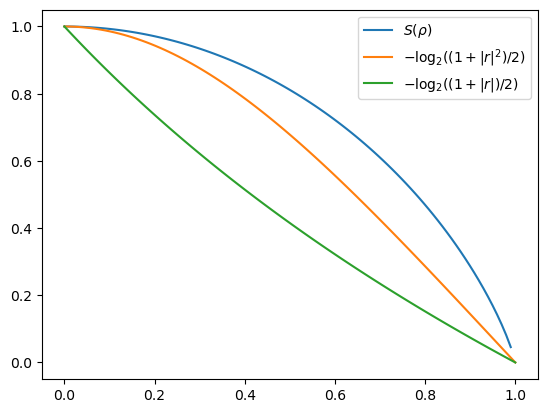

S is bigger than S3
S is bigger than S2
0.5441934976682178 0.5132025207539144


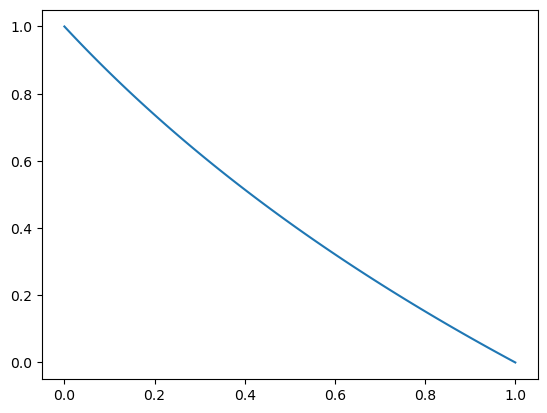

C:\Users\18349\AppData\Local\Temp\ipykernel_572228\3410704132.py:43: RuntimeWarning: divide by zero encountered in log
  plt.plot(r, [0.5*np.log((1-x)/(1+x))+2*x/(1+x**2) for x in r])


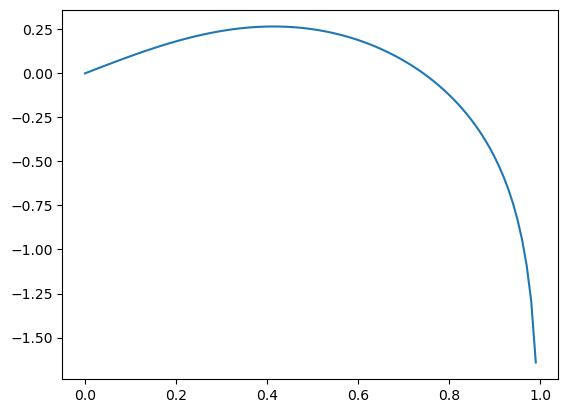

C:\Users\18349\AppData\Local\Temp\ipykernel_572228\3410704132.py:45: RuntimeWarning: divide by zero encountered in double_scalars
  plt.plot(r, [-1/(1-x**2)+2*(1-x**2)/(1+x**2)**2 for x in r])


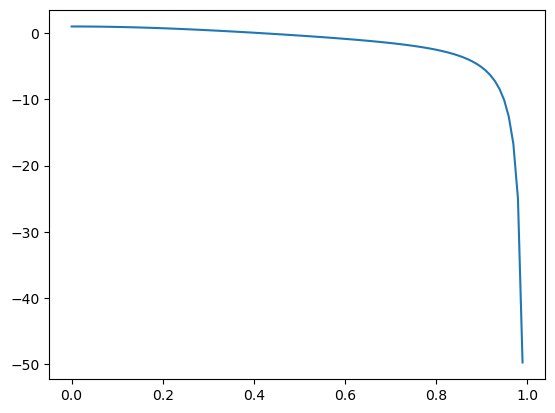

In [15]:
import numpy as np
import matplotlib.pyplot as plt

n = 2 # r的几次方,n=3上面的不等式就不成立了，图示就能得到。

r = np.linspace(0,1,100)
S = [-(1+x)/2*np.log2((1+x)/2)-(1-x)/2*np.log2((1-x)/2) for x in r]
S2 = [-np.log2((1+x**n)/2) for x in r]
S3 = [-np.log2((1+x)/2) for x in r]
S4 = [-(1+x)/2*np.log2((1+x)/2) for x in r]
plt.plot(r,S,label=r'$S(\rho)$')
plt.plot(r,S2,label=r'$-\log_2((1+\vert r\vert^2)/2)$')
plt.plot(r,S3,label=r'$-\log_2((1+\vert r\vert)/2)$')
#plt.ylim([0,1])
# plt.yscale('log')
plt.legend()
plt.show()

flag =True
for i in range(len(r)):
    if S[i]<S3[i]:
        flag=False#print('S is bigger than S3')
        break
if flag==True:
    print('S is bigger than S3')

flag = True
for i in range(len(r)):
    if S[i]<S2[i]:
        flag = False# print('S is bigger than S3')
        break
if flag==True:
    print('S is bigger than S2')

r_list = np.random.random(100)
#y1 = [-(1+x)/2*np.log2((1+x)/2)-(1-x)/2*np.log2((1-x)/2) for x in r_list]
y2 = [-np.log2((1+x**n)/2) for x in r_list]
print(np.average(y2), -np.log2((1+np.average(np.abs(r_list)**n))/2))

plt.plot(np.abs(r)**2, [-np.log2((1+x**2)/2) for x in r])
plt.show()

plt.plot(r, [0.5*np.log((1-x)/(1+x))+2*x/(1+x**2) for x in r])
plt.show()
plt.plot(r, [-1/(1-x**2)+2*(1-x**2)/(1+x**2)**2 for x in r])
plt.show()

In [33]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Operator
from scipy.linalg import expm
import numpy as np
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Operator, Statevector

# 创建量子电路并应用演化算符
qc = QuantumCircuit(3)
qc.cx(0,2)
qc.cx(1,2)
operator = Operator(qc)
matrix = operator.data
print(matrix[:4,:4])
print(matrix)

# 创建量子电路并应用演化算符
qc = QuantumCircuit(3)
qc.cx(0,2)
qc.cx(1,2)
qc.cx(2,1)
operator = Operator(qc)
matrix = operator.data
print(matrix[:4,:4])
print(matrix)

x = np.array([[0.,1.],[1.,0.]])
print(np.dot(np.kron(x, np.identity(2)), np.array([[0,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,0]])))

print(np.dot(np.kron(np.identity(2),x), np.array([[0,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,0]])))

[[1.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 1.+0.j]]
[[1.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 1.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 1.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j 1.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 1.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 1.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 1.+0.j]]
[[1.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 1.+0.j]]
[[1.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 1.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 1.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 1.+0.j 0.+0.j 0.+0.j 0.+0

In [2]:
current_state =  np.array([1/np.sqrt(2), 1/np.sqrt(2)], dtype=np.complex128)
qc = QuantumCircuit(1)
qc.initialize(current_state, 0)  # 在量子比特 0 上初始化为该状态
qc.x([0])
qc.save_state()

simulator = AerSimulator(
        method='statevector',
        device='GPU' if 'GPU' in AerSimulator().available_devices() else 'CPU',
        max_parallel_threads=1,
    )
compiled_qc = transpile(qc, simulator)
#current_state = Statevector(current_state)
evolved = simulator.run(
            compiled_qc,
            shots=1,
            initial_state=current_state,
            memory=True
        ).result().data() # get_statevector() # data['statevector'] 
print(evolved, compiled_qc.draw())
# initial_statevector=np.array([0.70710678, 0.70710678], dtype=np.complex128),




# 创建量子电路
qc = QuantumCircuit(1)

# 明确初始化量子比特的状态为 [0.70710678, 0.70710678]，即 1/sqrt(2) * (|0> + |1>)
initial_state = np.array([0.70710678, 0.70710678], dtype=np.complex128)
qc.initialize(current_state, 0)  # 在量子比特 0 上初始化为该状态

qc.x(0)  # 对量子比特 0 应用 X 门
qc.save_state()  # 保存量子状态

# 选择设备 (GPU 或 CPU)
simulator = AerSimulator(
    method='statevector',
    device='GPU' if 'GPU' in AerSimulator().available_devices() else 'CPU',
    max_parallel_threads=1,
)

# 编译电路
compiled_qc = transpile(qc, simulator)

# 使用模拟器运行量子电路
result = simulator.run(
    compiled_qc,
    shots=1,
    memory=True
).result()

# 获取模拟结果
evolved = result.data()

# 打印结果
print(evolved)



NameError: name 'np' is not defined

In [6]:
import numpy as np
from scipy.linalg import expm
x = np.random.random(100)*10
print(np.average((x**2)), np.average(x)**2)

sigma_y = np.array([[0,-1j],[1j,0]])
t_final = 1
Ry = expm(-1j*sigma_y*t_final)
Ry_ = expm(1j*sigma_y*t_final)
iden_i = np.array([[1,0],[0,1]])
CNOT = np.array([[1,0,0,0],[0,1,0,0],[0,0,0,1],[0,0,1,0]])
CNOT2 = np.array([[1,0,0,0],[0,0,0,1],[0,0,1,0],[0,1,0,0]])
a = np.dot( np.kron(iden_i, Ry_), np.dot(CNOT, np.dot(np.kron(iden_i, Ry), CNOT)))
print(a)
print(np.dot(CNOT2, np.dot(a,CNOT2)))
print(np.dot(CNOT,CNOT2))

29.627185786913774 21.965528761479828
[[ 1.        +0.j  0.        +0.j  0.        +0.j  0.        +0.j]
 [ 0.        +0.j  1.        +0.j  0.        +0.j  0.        +0.j]
 [ 0.        +0.j  0.        +0.j -0.41614684+0.j  0.90929743+0.j]
 [ 0.        +0.j  0.        +0.j -0.90929743+0.j -0.41614684+0.j]]
[[ 1.        +0.j  0.        +0.j  0.        +0.j  0.        +0.j]
 [ 0.        +0.j -0.41614684+0.j -0.90929743+0.j  0.        +0.j]
 [ 0.        +0.j  0.90929743+0.j -0.41614684+0.j  0.        +0.j]
 [ 0.        +0.j  0.        +0.j  0.        +0.j  1.        +0.j]]
[[1 0 0 0]
 [0 0 0 1]
 [0 1 0 0]
 [0 0 1 0]]


d:\anaconda3\envs\QuantumPhysics\lib\site-packages\qiskit\visualization\circuit\qcstyle.py:342: UserWarning: style option/s (text) is/are not supported
  set_style(current_style, style)


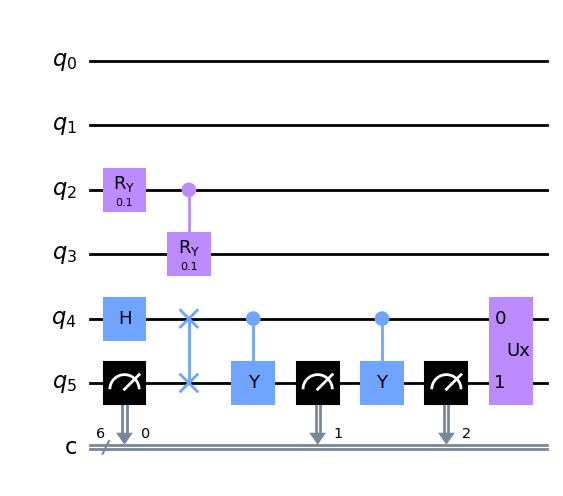

In [29]:
from qiskit import QuantumCircuit, Aer, execute
# from qiskit.circuit.library import RYGate
from qiskit.quantum_info import Operator, Statevector

# Create a Quantum Circuit with 6 qubits and 6 classical bits
qc = QuantumCircuit(6, 6)

# Apply Hadamard gate on qubit 4
qc.h(4)

# Measure qubit 5 to classical bit 0
qc.measure(5, 0)

# Swap qubit 4 and qubit 5
qc.swap(4, 5)

# Apply Controlled-Y gate on qubits 4 and 5
qc.cy(4, 5)

# Measure qubit 5 to classical bit 1
qc.measure(5, 1)

# Apply Controlled-Y gate on qubits 4 and 5
qc.cy(4, 5)

qc.ry(0.1, 2)  # 将0.1替换为$\theta$
qc.cry(0.1, 2, 3)  # 将0.1替换为$\theta$
# qc.data[0] = (RYGate('$\\theta$').control(0), [2])  # 修改第一个RY门的标签为 \\theta


# Measure qubit 5 to classical bit 2
qc.measure(5, 2)
Hx = np.zeros((4, 4), dtype=np.complex128)
Hx[1, 2] = 1/2
Hx[2, 1] = 1/2
Ux = expm(-1j * Hx * 1)
qc.unitary(Operator(Ux), [4,5], label='Ux')


# Draw the circuit
qc.draw('mpl', style={'text': {'ry': '$\theta$'}})


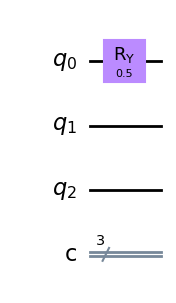